# Repeat Purchase Prediction (90-Day)
**Assignment pipeline:** I. Data Import & EDA → II. Cleaning & Pre-processing → III. Feature Selection → IV. Model Selection & Assessment → V. Final Output

> Cells marked `====missing work here=====` are not done yet.

---
# I. Data Import & Exploratory Data Analysis (EDA)
## I.1 Data Integration
Load `train.csv` (6,534 historical records) and `test.csv` (986 records), then join the optional `clientes.csv` table using `customer_id`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from IPython.display import display
from matplotlib.ticker import StrMethodFormatter

DATA_DIR = "../data"

#fixed dataframes are fixed dataframes that wont be modified, deleted , or merged 
fixed_train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
fixed_clients=pd.read_csv(os.path.join(DATA_DIR, "clientes.csv"))

test = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

clients = fixed_clients.copy()
train = fixed_train.copy()

print(f"train shape: {train.shape}")
print(f"test shape: {test.shape}")
print(f"clients shape: {clients.shape}")

train shape: (6534, 39)
test shape: (986, 38)
clients shape: (1143, 13)


In [3]:
train.head(5)

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


In [4]:
clients.head(5)

,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


In [5]:
print(f"===Train dataset Features ({len(train.columns)-1} Features)===")
for i in range(0, len(train.columns), 3):
    print(train.columns[i:i+3].tolist())
print(f"===Client dataset Features ({len(clients.columns)} Features)===")
for i in range(0, len(clients.columns), 3):
    print(clients.columns[i:i+3].tolist())

===Train dataset Features (38 Features)===
['Total a Pagar', 'Total Bruto', 'Total Liquido']
['Total Imp_', 'Total Portes', 'Total Desc_ Global']
['Total Desc_ Linha', 'Custo', 'N_ Detalhes']
['invoice_count_current_purchase', 'repeat_purchase_90d', 'days_since_previous_purchase']
['customer_tenure_days', 'prior_purchase_count', 'prior_total_spend']
['prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value']
['prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days']
['purchase_count_30d', 'spend_30d', 'purchase_count_90d']
['spend_90d', 'purchase_count_180d', 'spend_180d']
['purchase_count_365d', 'spend_365d', 'customer_id']
['payment_type', 'salesperson', 'commercial_zone']
['transport_method', 'warehouse', 'document_series']
['purchase_date', 'ID', 'random_noise']
===Client dataset Features (13 Features)===
['customer_id', 'country_or_region', 'commercial_region']
['island', 'municipality', 'city']
['postal_area', 'postal_code', 'street']
['ad

In [6]:
# Merge clients into train on customer_id
train = train.merge(clients, on='customer_id', how='left')

fixed_merged=fixed_train.merge(fixed_clients,on="customer_id",how='left')

## I.2 Exploration: Descriptive Statistics
### Target distribution
The goal is binary classification:
- **1**: yes, the customer is expected to buy in the next 90 days
- **0**: no, the customer is not expected to buy in the next 90 days

In [7]:
labelcount = train['repeat_purchase_90d'].value_counts().sort_index()
class0_percentage = labelcount[0]/(labelcount[0]+labelcount[1])
class1_percentage = labelcount[1]/(labelcount[0]+labelcount[1])
print(f"{labelcount}")
print(f"class 0 proportion {class0_percentage*100:.2f} %")
print(f"class 1 proportion {class1_percentage*100:.2f} %")

repeat_purchase_90d
0    2880
1    3654
Name: count, dtype: int64
class 0 proportion 44.08 %
class 1 proportion 55.92 %


Pretty balanced classes.

### Data understanding
**Current Purchase and Invoice Features**
The `Total Bruto` (Gross Total), `Total Liquido` (Net Total), and `Total a Pagar` (Total Amount Due) fields describe the purchase amount at different stages. `Total Imp_` is tax, `Total Portes` is shipping, and `Total Desc_ Global` and `Total Desc_ Linha` are discounts applied to the whole invoice and to individual lines. `Custo` records cost. `N_ Detalhes` counts invoice detail lines, while `invoice_count_current_purchase` counts invoices associated with the current purchase.

**Customer Purchase History**
`prior_purchase_count` and `prior_total_spend` summarize how many purchases the customer made before and how much they spent in total. The `prior_*_purchase_value` features summarize the values of those earlier purchases using the mean, standard deviation, minimum, and maximum.

**Purchase Timing**
`customer_tenure_days` is how long the customer has been in the records. `days_since_previous_purchase` measures the time since their last purchase; `prior_mean_gap_days` and `prior_std_gap_days` summarize the average time between earlier purchases and how much that gap varied.

**Rolling Purchase Features**
The `purchase_count_*` features count how many purchases a customer made within the matching 30-, 90-, 180-, or 365-day look-back window. The corresponding `spend_*` features add up the customer's spending over that same window.

**Random Noise**
`random_noise` appears to be a randomly generated numeric feature rather than a meaningful customer or purchase measure.

### Categorical / numerical split
We are not excluding the clients dataset here, just viewing feature data cleanliness.

In [8]:
train.dtypes

Total a Pagar                     float64
Total Bruto                       float64
Total Liquido                     float64
Total Imp_                        float64
Total Portes                      float64
Total Desc_ Global                float64
Total Desc_ Linha                 float64
Custo                             float64
N_ Detalhes                       float64
invoice_count_current_purchase    float64
repeat_purchase_90d                 int64
days_since_previous_purchase      float64
customer_tenure_days              float64
prior_purchase_count              float64
prior_total_spend                 float64
prior_mean_purchase_value         float64
prior_std_purchase_value          float64
prior_min_purchase_value          float64
prior_max_purchase_value          float64
prior_mean_gap_days               float64
prior_std_gap_days                float64
purchase_count_30d                float64
spend_30d                         float64
purchase_count_90d                

In [9]:
categorical_cols = (
    train.select_dtypes(include=["object", "category", "string"])
         .columns.drop("purchase_date", errors="ignore")
         .tolist()
)

categorical_train = train[categorical_cols]
print(categorical_train.head(1))

# Check for missing values
categorical_null_counts = categorical_train.isna().sum()
categorical_null_counts = categorical_null_counts[categorical_null_counts > 0]

if categorical_null_counts.empty:
    print("No missing values in categorical features.")
else:
    print("Categorical features with missing values:")
    print(categorical_null_counts.sort_values(ascending=False))

                payment_type       salesperson              commercial_zone  \
0  Maybe Tomorrow Payment 10  VLOOKUP Master 9  Decorative Dashboard Zone 4   

             transport_method                warehouse  document_series  \
0  Maybe Tomorrow Delivery 61  Final Excel Warehouse 1  Ctrl Z Series 2   

                         country_or_region               commercial_region  \
0  Country CT10: Land of The Final Version  Region RG25: We Will See Later   

  island                                     municipality  \
0    NaN  Municipality MU89: Council of Last Minute Edits   

                              city                             postal_area  \
0  City CY286: Cached Result Falls  Postal area PA228: Hidden Sheet Sector   

                               postal_code  \
0  Postal code PC444: #REF! Delivery Route   

                                     street  \
0  Street ST303: Absolute Reference Terrace   

                              address                      compan

### Numerical feature summary (raw, before cleaning)

In [10]:
target = "repeat_purchase_90d"
exclude = [target, "customer_id", "ID"]

numerical_cols = (
    train.select_dtypes(include="number")
         .columns.drop(exclude, errors="ignore")
         .tolist()
)

numerical_train = train[numerical_cols]
numerical_summary = numerical_train.describe().T.rename(
    columns={"50%": "median"}
)
numerical_summary["missing"] = numerical_train.isna().sum()
numerical_summary["IQR"] = numerical_summary["75%"] - numerical_summary["25%"]
numerical_summary = numerical_summary[
    ["count", "missing", "mean", "std", "min", "25%", "median", "75%", "max", "IQR"]
]
print(numerical_summary.to_string(float_format=lambda value: f"{value:,.2f}"))

right_skew = [c for c in numerical_cols if numerical_train[c].skew() > 1]
left_skew = [c for c in numerical_cols if numerical_train[c].skew() < -1]
print(f"\n{len(right_skew)} right-skewed (skew > 1): {right_skew}")
print(f"{len(left_skew)} left-skewed  (skew < -1): {left_skew}")

                                  count  missing         mean           std         min      25%   median       75%              max       IQR
Total a Pagar                  6,469.00       65       925.56      1,335.00        0.93   188.92   476.74  1,087.67        22,297.21    898.75
Total Bruto                    6,469.00       65       886.15      1,327.64        0.83   175.74   445.74  1,036.70        21,578.28    860.96
Total Liquido                  6,469.00       65       773.34      1,136.36        0.76   154.38   389.91    903.37        18,127.81    748.99
Total Imp_                     6,469.00       65       152.22        225.26        0.00    29.93    79.74    184.84         4,169.40    154.91
Total Portes                   6,469.00       65         1.15          5.84        0.00     0.00     0.00      0.00           181.06      0.00
Total Desc_ Global             6,469.00       65         0.35          5.12        0.00     0.00     0.00      0.00           218.49      0.00

## I.3 Relationship Mapping
### Univariate analysis vs. `repeat_purchase_90d`
> Note: these run on the merged but **not yet cleaned** data. Cleaning is in Section II.

#### Categorical features (train)

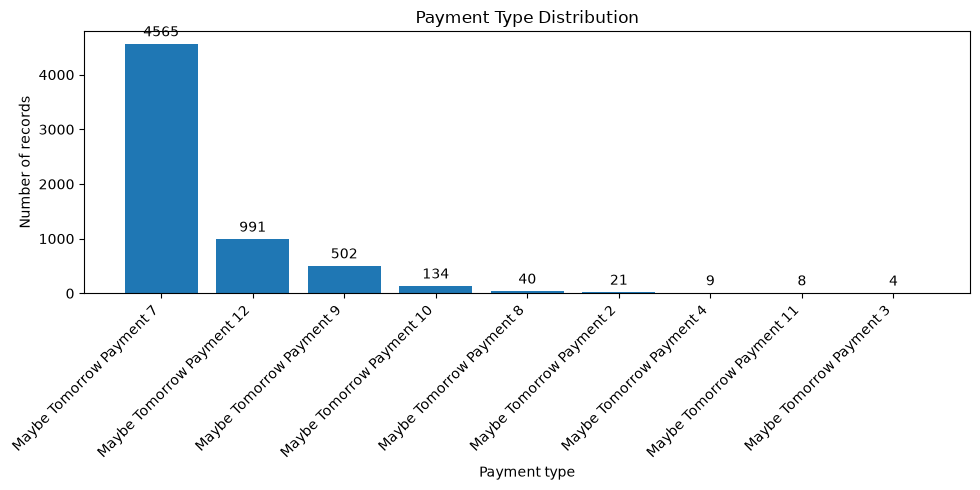

In [11]:
payment_type = categorical_train["payment_type"]
payment_counts = payment_type.value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(payment_counts.index, payment_counts.values)

ax.set_title("Payment Type Distribution")
ax.set_xlabel("Payment type")
ax.set_ylabel("Number of records")
ax.tick_params(axis="x", labelrotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
ax.bar_label(ax.containers[0], padding=3)

fig.tight_layout()
plt.show()

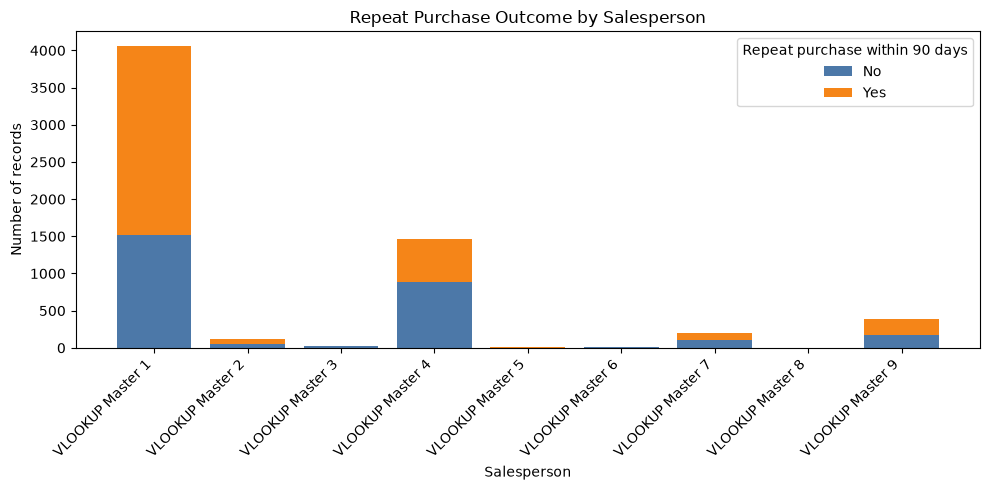

In [12]:
salesperson_target_counts = pd.crosstab(
    train["salesperson"], train["repeat_purchase_90d"]
).reindex(columns=[0, 1], fill_value=0)

x = np.arange(len(salesperson_target_counts))
no_counts = salesperson_target_counts[0]
yes_counts = salesperson_target_counts[1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x, no_counts, label="No", color="#4C78A8")
ax.bar(x, yes_counts, bottom=no_counts, label="Yes", color="#F58518")

ax.set_title("Repeat Purchase Outcome by Salesperson")
ax.set_xlabel("Salesperson")
ax.set_ylabel("Number of records")
ax.set_xticks(x, salesperson_target_counts.index, rotation=45, ha="right")
ax.legend(title="Repeat purchase within 90 days")

fig.tight_layout()
plt.show()

The salesperson might affect the label (logically meaningful, but not statistically proven yet).

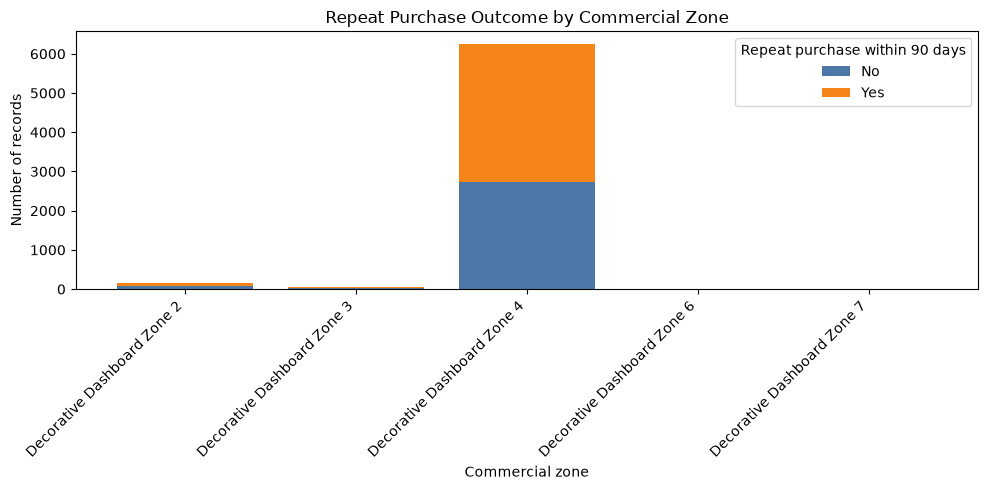

In [13]:
commercial_zone_target_counts = pd.crosstab(
    train["commercial_zone"], train["repeat_purchase_90d"]
).reindex(columns=[0, 1], fill_value=0)

x = np.arange(len(commercial_zone_target_counts))
no_counts = commercial_zone_target_counts[0]
yes_counts = commercial_zone_target_counts[1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x, no_counts, label="No", color="#4C78A8")
ax.bar(x, yes_counts, bottom=no_counts, label="Yes", color="#F58518")

ax.set_title("Repeat Purchase Outcome by Commercial Zone")
ax.set_xlabel("Commercial zone")
ax.set_ylabel("Number of records")
ax.set_xticks(x, commercial_zone_target_counts.index, rotation=45, ha="right")
ax.legend(title="Repeat purchase within 90 days")

fig.tight_layout()
plt.show()

**`commercial_zone` has a highly skewed category distribution: nearly all non-missing observations are in Zone 4, with very few in the other zones.**

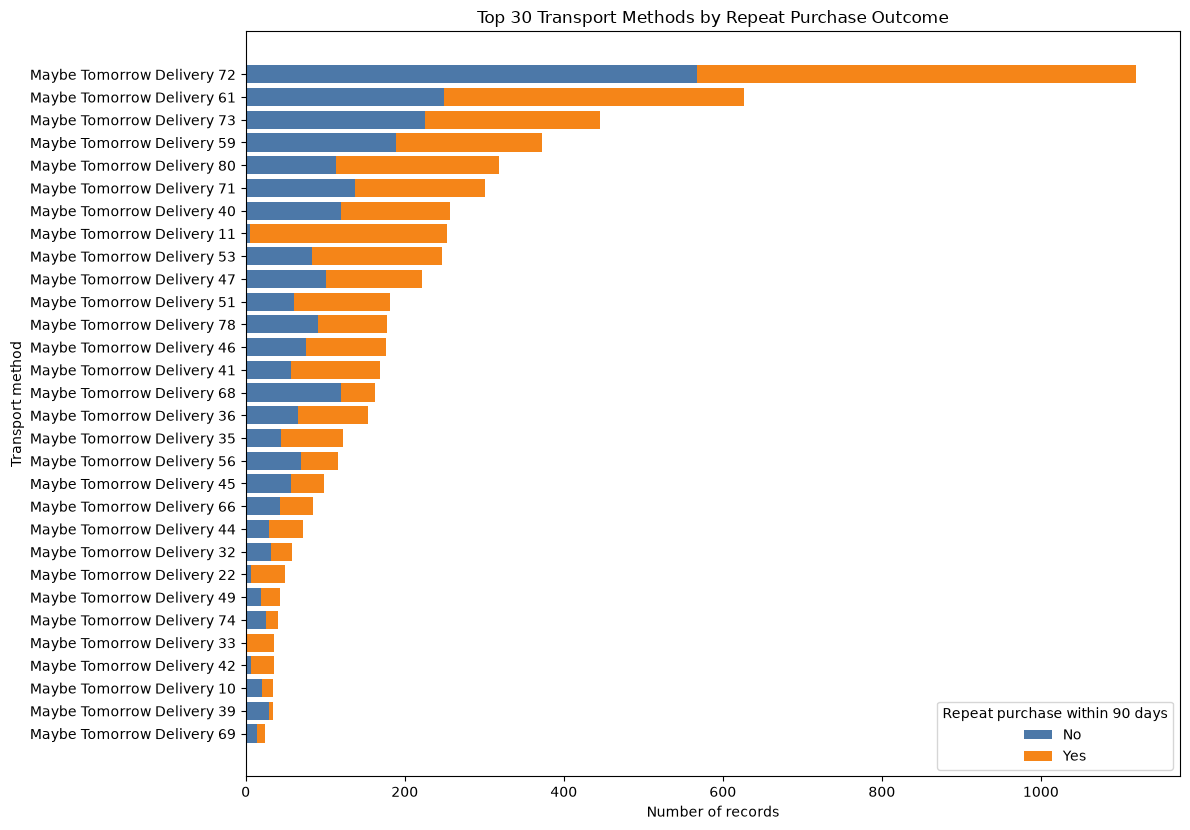

In [14]:
transport_method_target_counts = pd.crosstab(
    train["transport_method"], train["repeat_purchase_90d"]
).reindex(columns=[0, 1], fill_value=0)
transport_method_target_counts = transport_method_target_counts.loc[
    transport_method_target_counts.sum(axis=1).nlargest(30).index
]

y = np.arange(len(transport_method_target_counts))
no_counts = transport_method_target_counts[0]
yes_counts = transport_method_target_counts[1]

fig, ax = plt.subplots(
    figsize=(12, max(7, len(transport_method_target_counts) * 0.28))
)
ax.barh(y, no_counts, label="No", color="#4C78A8")
ax.barh(y, yes_counts, left=no_counts, label="Yes", color="#F58518")

ax.set_title("Top 30 Transport Methods by Repeat Purchase Outcome")
ax.set_xlabel("Number of records")
ax.set_ylabel("Transport method")
ax.set_yticks(y, transport_method_target_counts.index)
ax.invert_yaxis()
ax.legend(title="Repeat purchase within 90 days")

fig.tight_layout()
plt.show()

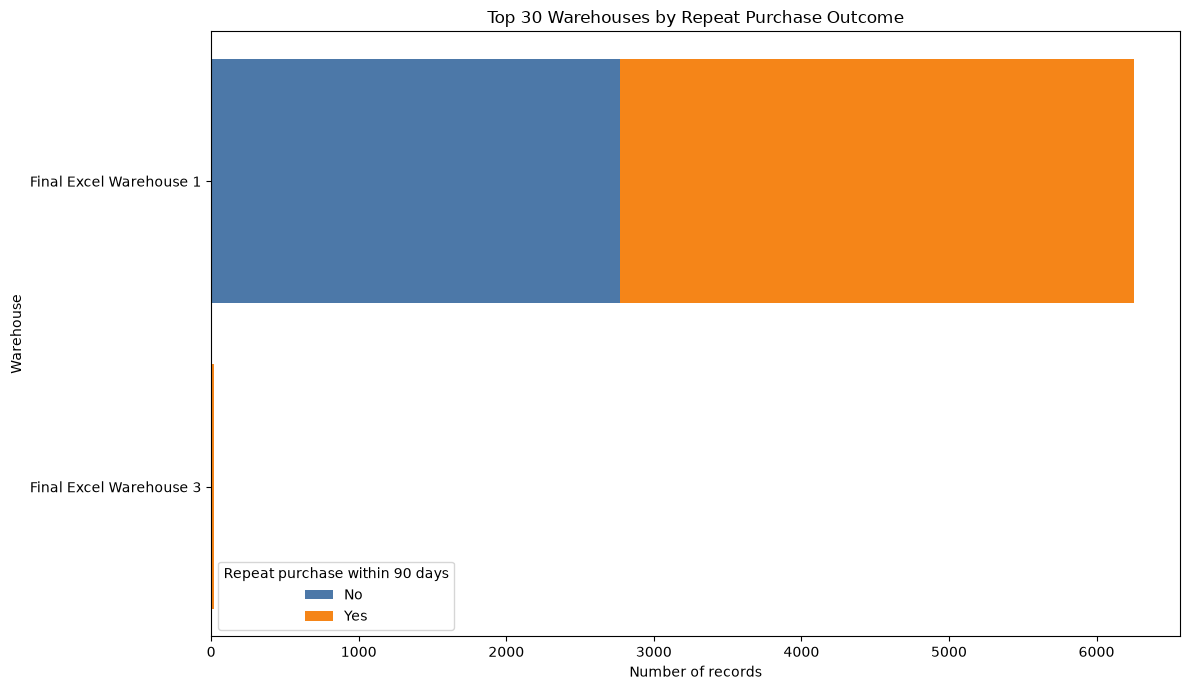

In [15]:
warehouse_target_counts = pd.crosstab(
    train["warehouse"], train["repeat_purchase_90d"]
).reindex(columns=[0, 1], fill_value=0)
warehouse_target_counts = warehouse_target_counts.loc[
    warehouse_target_counts.sum(axis=1).nlargest(30).index
]

y = np.arange(len(warehouse_target_counts))
no_counts = warehouse_target_counts[0]
yes_counts = warehouse_target_counts[1]

fig, ax = plt.subplots(
    figsize=(12, max(7, len(warehouse_target_counts) * 0.28))
)
ax.barh(y, no_counts, label="No", color="#4C78A8")
ax.barh(y, yes_counts, left=no_counts, label="Yes", color="#F58518")

ax.set_title("Top 30 Warehouses by Repeat Purchase Outcome")
ax.set_xlabel("Number of records")
ax.set_ylabel("Warehouse")
ax.set_yticks(y, warehouse_target_counts.index)
ax.invert_yaxis()
ax.legend(title="Repeat purchase within 90 days")

fig.tight_layout()
plt.show()

`warehouse` should probably be discarded: nearly all records are Warehouse 1, and Warehouse 3 is too small to learn patterns from.

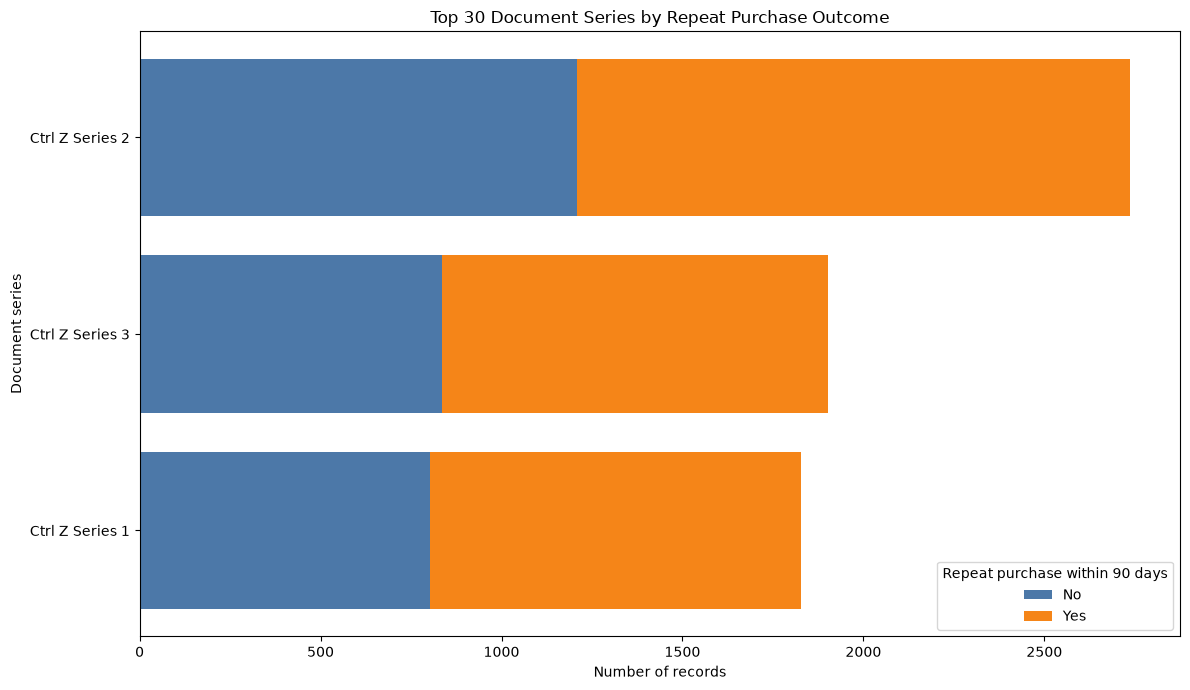

In [16]:
document_series_target_counts = pd.crosstab(
    train["document_series"], train["repeat_purchase_90d"]
).reindex(columns=[0, 1], fill_value=0)
document_series_target_counts = document_series_target_counts.loc[
    document_series_target_counts.sum(axis=1).nlargest(30).index
]

y = np.arange(len(document_series_target_counts))
no_counts = document_series_target_counts[0]
yes_counts = document_series_target_counts[1]

fig, ax = plt.subplots(
    figsize=(12, max(7, len(document_series_target_counts) * 0.28))
)
ax.barh(y, no_counts, label="No", color="#4C78A8")
ax.barh(y, yes_counts, left=no_counts, label="Yes", color="#F58518")

ax.set_title("Top 30 Document Series by Repeat Purchase Outcome")
ax.set_xlabel("Number of records")
ax.set_ylabel("Document series")
ax.set_yticks(y, document_series_target_counts.index)
ax.invert_yaxis()
ax.legend(title="Repeat purchase within 90 days")

fig.tight_layout()
plt.show()

#### Client features (from `clientes.csv`)

Clients dataset shape: (1143, 13)

Client dataset preview:


,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015



NaN values per client feature:
customer_type          1143
street                  598
island                  578
city                    546
postal_code             170
municipality            159
commercial_region       114
postal_area              71
address                   6
customer_id               0
country_or_region         0
company_name              0
customer_since_year       0

Client numerical feature summary:
                       count  missing     mean  std      min      25%   median      75%      max  IQR
customer_since_year 1,143.00        0 2,017.00 2.97 2,015.00 2,015.00 2,015.00 2,018.00 2,026.00 3.00
Joined shape: (6534, 51)
Rows matched to a client: 6,534 / 6,534

Repeat-purchase rate by common client categories (minimum 30 records):
          feature                                        category  records repeat_rate
country_or_region         Country CT10: Land of The Final Version     6321       56.5%
country_or_region          Country CT5: Land of The Fi

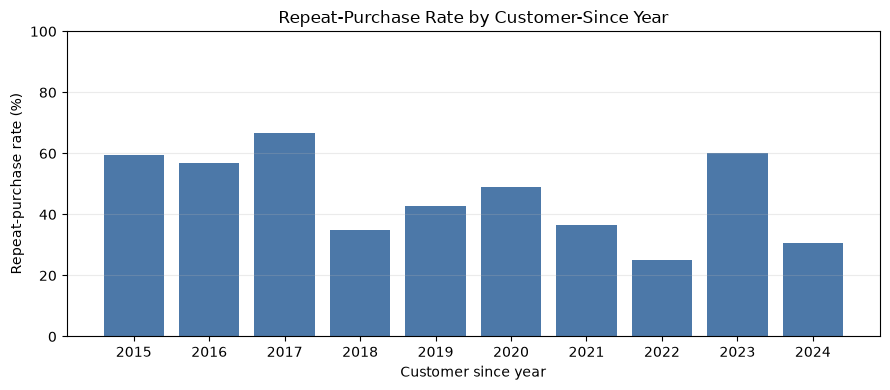

In [17]:
print("Clients dataset shape:", clients.shape)
print("\nClient dataset preview:")
display(clients.head())

client_missing_counts = clients.isna().sum().sort_values(ascending=False)
print("\nNaN values per client feature:")
print(client_missing_counts.to_string())

client_numeric_cols = [
    column for column in clients.select_dtypes(include="number").columns
    if column != "customer_id" and clients[column].notna().any()
]
client_numerical = clients[client_numeric_cols]
client_summary = client_numerical.describe().T.rename(
    columns={"50%": "median"}
)
client_summary["missing"] = client_numerical.isna().sum()
client_summary["IQR"] = client_summary["75%"] - client_summary["25%"]
client_summary = client_summary[
    ["count", "missing", "mean", "std", "min", "25%", "median", "75%", "max", "IQR"]
]
print("\nClient numerical feature summary:")
print(client_summary.to_string(float_format=lambda value: f"{value:,.2f}"))

matched_clients = train["country_or_region"].notna().sum()
print(f"Joined shape: {train.shape}")
print(f"Rows matched to a client: {matched_clients:,} / {len(train):,}")

client_categorical_features = [
    column for column in clients.select_dtypes(include=["object", "category", "string"]).columns
    if clients[column].notna().any() and column in train.columns
]
minimum_category_rows = 30
maximum_categories = 5
relationship_tables = []

for feature in client_categorical_features:
    categories = train[feature].astype("string").fillna("Missing")
    common_categories = categories.value_counts()
    common_categories = common_categories[common_categories >= minimum_category_rows]
    common_categories = common_categories.head(maximum_categories).index
    grouped_categories = categories.where(categories.isin(common_categories), "Other / rare")
    feature_summary = (
        pd.DataFrame({"category": grouped_categories,
                      "repeat_purchase_90d": train[target]})
        .groupby("category")["repeat_purchase_90d"]
        .agg(records="size", repeat_rate="mean")
        .reset_index()
    )
    feature_summary.insert(0, "feature", feature)
    relationship_tables.append(feature_summary)

client_category_relationships = pd.concat(relationship_tables, ignore_index=True)
client_category_relationships["repeat_rate"] *= 100
print("\nRepeat-purchase rate by common client categories (minimum 30 records):")
print(client_category_relationships.to_string(
    index=False,
    formatters={"repeat_rate": "{:.1f}%".format},
))

year_summary = (
    train.groupby("customer_since_year")["repeat_purchase_90d"]
    .agg(records="size", repeat_rate="mean")
)
year_summary["repeat_rate"] *= 100
print("\nRepeat-purchase rate by customer-since year:")
print(year_summary.to_string(formatters={"repeat_rate": "{:.1f}%".format}))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(year_summary.index.astype(str), year_summary["repeat_rate"], color="#4C78A8")
ax.set_title("Repeat-Purchase Rate by Customer-Since Year")
ax.set_xlabel("Customer since year")
ax.set_ylabel("Repeat-purchase rate (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

The bars show the **observed repeat-purchase rate** for each country or region:

$$\text{repeat rate} = \frac{\text{customers with repeat\_purchase\_90d = 1}}{\text{customers in that group}} \times 100$$

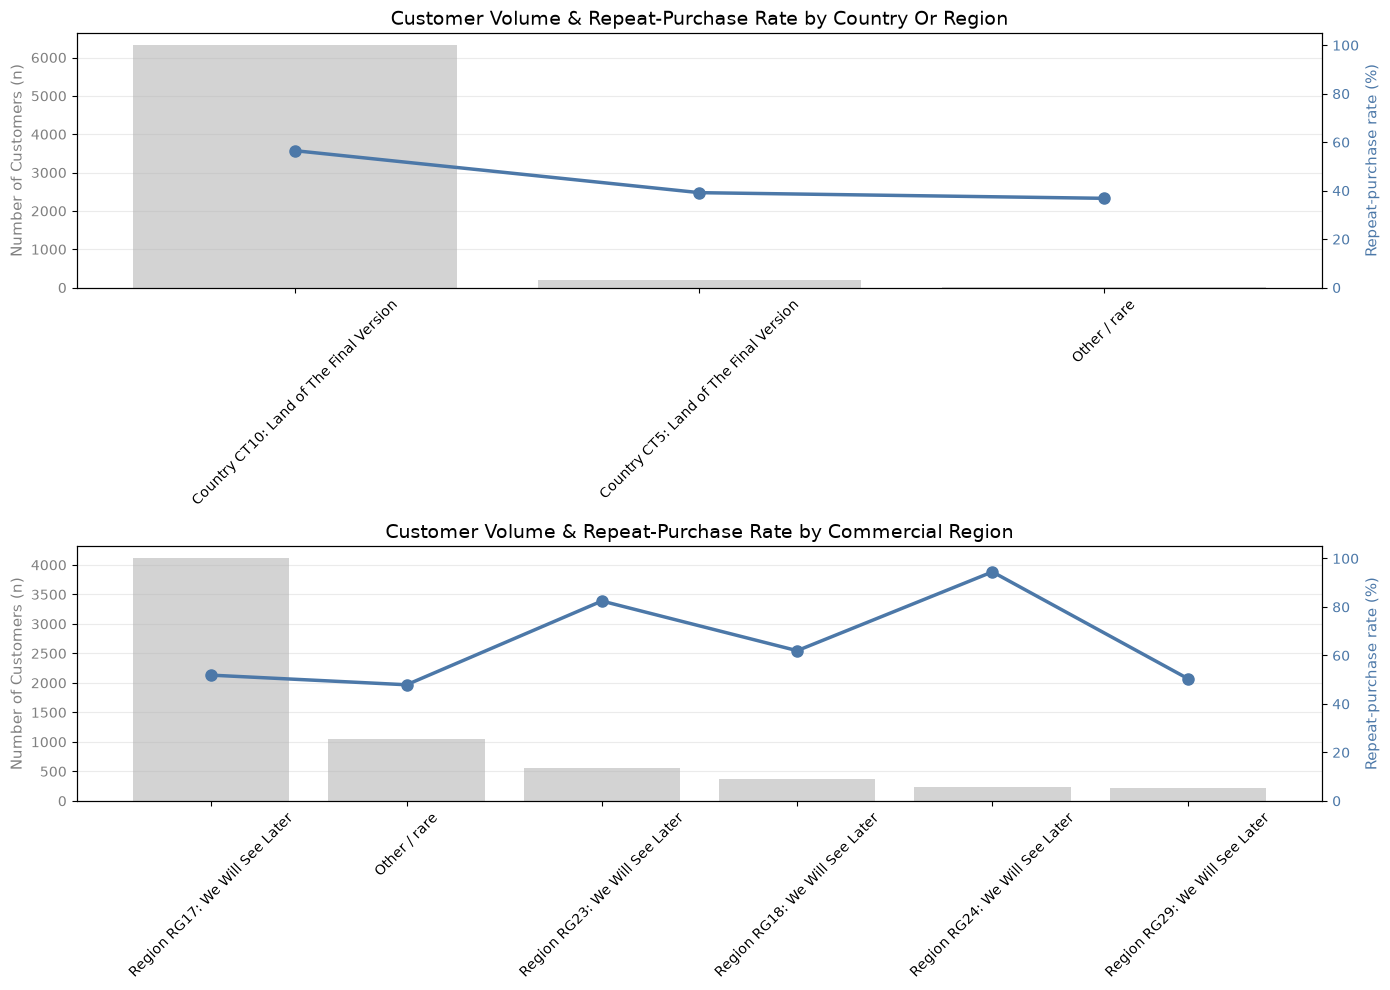

In [18]:
location_features = ["country_or_region", "commercial_region"]
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

for ax1, feature in zip(axes, location_features):
    summary = client_category_relationships[
        client_category_relationships["feature"] == feature
    ].sort_values("records", ascending=False)

    categories = summary["category"]
    records = summary["records"]
    rates = summary["repeat_rate"]

    # 1st axis: number of customers (bars)
    ax1.bar(categories, records, color="#d3d3d3", label="Number of Customers")
    ax1.set_ylabel("Number of Customers (n)", color="gray", fontsize=11)
    ax1.tick_params(axis='y', labelcolor="gray")
    ax1.tick_params(axis='x', rotation=45)
    ax1.grid(axis="y", alpha=0.25)

    # 2nd axis: repeat rate (line)
    ax2 = ax1.twinx()
    ax2.plot(categories, rates, color="#4C78A8", marker='o', linewidth=2.5, markersize=8, label="Repeat Rate (%)")
    ax2.set_ylabel("Repeat-purchase rate (%)", color="#4C78A8", fontsize=11)
    ax2.set_ylim(0, 105)
    ax2.tick_params(axis='y', labelcolor="#4C78A8")

    ax1.set_title(f"Customer Volume & Repeat-Purchase Rate by {feature.replace('_', ' ').title()}", fontsize=14)

fig.tight_layout()
plt.show()

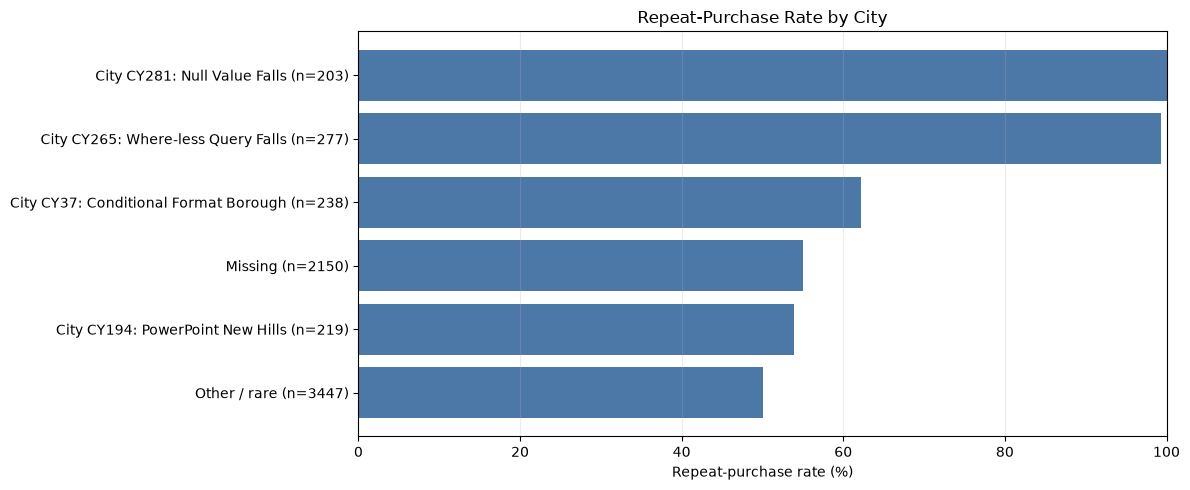


Distinct customers by city group (repeat_purchase_90d = 1 at least once):
                                       customers  repeat_buyers
city_group                                                     
Other / rare                                 352            207
City CY194: PowerPoint New Hills              11              9
Missing                                      236            126
City CY37: Conditional Format Borough          9              8
City CY265: Where-less Query Falls             1              1
City CY281: Null Value Falls                   1              1


In [19]:
city_summary = client_category_relationships[
    client_category_relationships["feature"] == "city"
].sort_values("repeat_rate")
city_labels = [
    f"{category} (n={records})"
    for category, records in zip(city_summary["category"], city_summary["records"])
]

fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(city_labels, city_summary["repeat_rate"], color="#4C78A8")
ax.set_title("Repeat-Purchase Rate by City")
ax.set_xlabel("Repeat-purchase rate (%)")
ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

# Count each customer once, even if they have multiple positive training rows.
city_row_values = train["city"].astype("string").fillna("Missing")
common_city_categories = city_row_values.value_counts()
common_city_categories = common_city_categories[
    common_city_categories >= minimum_category_rows
].head(maximum_categories).index
customer_repeat_status = (
    fixed_train.groupby("customer_id")[target]
    .max()
    .rename("repeat_buyer")
    .reset_index()
)
buyers_by_city = clients[["customer_id", "city"]].merge(
    customer_repeat_status,
    on="customer_id",
    how="inner",
    validate="one_to_one",
)
buyer_city_values = buyers_by_city["city"].astype("string").fillna("Missing")
buyers_by_city["city_group"] = buyer_city_values.where(
    buyer_city_values.isin(common_city_categories), "Other / rare"
)
city_customer_counts = buyers_by_city.groupby("city_group").agg(
    customers=("customer_id", "nunique"),
    repeat_buyers=("repeat_buyer", "sum"),
).reindex(city_summary["category"], fill_value=0).astype(int)
city_customer_counts.index.name = "city_group"
print("\nDistinct customers by city group (repeat_purchase_90d = 1 at least once):")
print(city_customer_counts.to_string())

**Caution:** City CY281's 100% rate comes from 203 records for just one customer, not 203 different customers. It does not mean customers in that city always repeat. **This observation can be misleading.**

### Multivariate analysis
Correlation analysis (Spearman / Pearson) needs cleaned data, so the active version is in **Section III (Filter Methods, Numerical vs. Numerical)**. The earlier version on uncleaned data is kept below for reference.

In [20]:
# # unclean data
# correlation_data = fixed_train.merge(
#     clients,
#     on="customer_id",
#     how="left",
#     validate="many_to_one",
# )
# excluded_features = ["ID", "customer_id", "random_noise"]
# numeric_features = correlation_data.select_dtypes(include="number").drop(
#     columns=excluded_features, errors="ignore"
# )
# numeric_features = numeric_features.loc[
#     :, numeric_features.nunique(dropna=True) > 1
# ]
# corr_matrix = numeric_features.corr()
#
# plt.figure(figsize=(14, 12))
# sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
# plt.title("Correlation Matrix of Numeric Transaction and Client Features")
# plt.tight_layout()
# plt.show()
#
# print(corr_matrix["repeat_purchase_90d"].sort_values(ascending=False))

---
# II. Data Cleaning & Pre-processing
## II.1 Missing & Anomalous Data
We improve data quality by removing unexplainable entries and dropping irrelevant features (identifiers).

### Illogical / too-corrupted data
- **`spend_365d`** has an extreme value of -159,115.18€ (it can be negative for refunds, but this is extreme, especially if larger than total spend).
- **`prior_mean_purchase_value`** & **`spend_365d`** have values above total spend, which is unexplainable.
- **Illogical orderings:** `prior_total_spend` < `spend_365d`, or `spend_365d` < `spend_180d`, or `spend_180d` < `spend_90d`.

### Useless features
`commercial_zone`, `random_noise`

In [21]:
# Check the invoice equations. Tolerance of 0.01 accounts for 1-cent rounding differences
tolerance = 1e-2

# 1. Verify the Net Total (Total Liquido)
eq1_valid = np.isclose(
    train['Total Liquido'],
    train['Total Bruto'] - train['Total Desc_ Linha'] - train['Total Desc_ Global'],
    atol=tolerance,
    equal_nan=False
)

# 2. Verify the Final Payable Amount (Total a Pagar)
eq2_valid = np.isclose(
    train['Total a Pagar'],
    train['Total Liquido'] + train['Total Imp_'] + train['Total Portes'],
    atol=tolerance,
    equal_nan=False
)

# 3. Rows where either equation FAILS
corrupted_rows = train[~(eq1_valid & eq2_valid)]

print(f"Found {len(corrupted_rows)} rows with mathematical inconsistencies:")

cols_to_inspect = [
    'Total Bruto', 'Total Desc_ Linha', 'Total Desc_ Global',
    'Total Liquido', 'Total Imp_', 'Total Portes', 'Total a Pagar'
]
corrupted_rows[cols_to_inspect].sort_values(by="Total Bruto", ascending=False).head()

Found 1118 rows with mathematical inconsistencies:


,Total Bruto,Total Desc_ Linha,Total Desc_ Global,Total Liquido,Total Imp_,Total Portes,Total a Pagar
1808,12500.00,3720.00,0.0,8780.00,0.00,100.00,8780.00
3802,9323.35,3704.89,0.0,5618.46,0.00,45.00,5618.46
5542,7860.48,3386.82,0.0,4473.66,0.00,181.06,4473.66
1344,7001.34,2550.01,0.0,4451.33,1023.81,18.70,5475.14
665,5643.43,2193.48,0.0,3449.95,0.00,159.73,3449.95


**Too unclean; verify whether the 1 billion value is an error or actual.**

These rows are corrupted. Imputation (mean, median, KNN or 0) doesn't work well because the features depend on each other (gross total, net total, taxes, shipping) and would need massive transformation. Also the mean is ~1 billion while the maximum total paid is 102,493.92.

The best solution is to not force data transformation but to remove the outliers (bug).

### Missing values

In [22]:
train.isna().sum().sort_values(ascending=False)

customer_type                     6534
street                            3834
island                            2211
city                              2150
prior_std_gap_days                1478
prior_mean_gap_days               1308
prior_std_purchase_value          1113
prior_mean_purchase_value          862
days_since_previous_purchase       861
prior_max_purchase_value           668
prior_min_purchase_value           668
postal_area                        278
transport_method                   261
warehouse                          260
spend_365d                         260
payment_type                       260
salesperson                        259
postal_code                        225
municipality                       217
commercial_zone                     65
Total a Pagar                       65
spend_180d                          65
document_series                     65
purchase_date                       65
random_noise                        65
purchase_count_365d      

Auto-discarding these features due to too many missing values (also street is hard to predict from city or other features):
- `customer_type` (6534 missing)
- `street` (3834 missing)

Discarding due to irrelevance to model prediction:
- `ID`
- `customer_id`
- `random_noise`

In [23]:
#count number of NaN for each row 
missing_per_row = fixed_merged.isna().sum(axis=1)

#Count number of rows for how many features are missing
missing_per_row=missing_per_row.value_counts()

#Create a df for pure visualization
df_missing = (
    missing_per_row
    .rename_axis("n_features_missing")
    .reset_index(name="n_rows_affected")
)

#printed using to_string to remove the index(useless for presentation)
print(df_missing.sort_values("n_features_missing",ascending=False).to_string(index=False))


 n_features_missing  n_rows_affected
                 40                4
                 39               16
                 38               28
                 37               17
                 15                1
                 14                9
                 13               15
                 12               24
                 11               64
                 10              216
                  9              227
                  8               95
                  7               84
                  6              245
                  5              329
                  4              719
                  3             1782
                  2             1950
                  1              709


In [24]:
# Rows that have more than 15 missing values
heavy_missing_rows = train[train.isna().sum(axis=1) > 9]

print(f"Number of rows missing 15+ features : {heavy_missing_rows[[ 'purchase_date', 'Total a Pagar']].size} these rows are to be deleted, its missing almost all features except in customer. \n")
heavy_missing_rows.head(3)

Number of rows missing 15+ features : 788 these rows are to be deleted, its missing almost all features except in customer. 



,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
25,213.69,173.73,173.73,39.96,0.00,0.0,0.0,108.080000,28.0,1.0,...,NaN,Municipality MU70: Council of Last Minute Edits,NaN,Postal area PA82: Hidden Sheet Sector,Postal code PC194: #REF! Delivery Route,Street ST275: AutoFill Junction,Address AD704: Cell Without a Home,NaN,Excel Is Not A Database Ltd 762,2015
27,41.38,33.64,33.64,7.74,4.89,0.0,0.0,3.750000,1.0,1.0,...,NaN,Municipality MU105: Council of Last Minute Edits,City CY304: Nested IF Junction,Postal area PA27: Hidden Sheet Sector,Postal code PC94: #REF! Delivery Route,NaN,Address AD794: Cell Without a Home,NaN,Excel Is Not A Database Ltd 486,2015
88,367.00,298.37,298.37,68.63,3.86,0.0,0.0,81.307198,28.0,1.0,...,NaN,Municipality MU57: Council of Last Minute Edits,NaN,Postal area PA178: Hidden Sheet Sector,Postal code PC363: #REF! Delivery Route,Street ST257: Null Value Parade,Address AD669: Cell Without a Home,NaN,Excel Is Not A Database Ltd 567,2016


In [25]:
# Features to drop
columns_to_drop = [
    'customer_type',
    'street',
    'ID',
    'customer_id',
    'random_noise'
]

train = train.drop(columns=columns_to_drop, errors='ignore')

n_dupes = train.duplicated().sum()
print(f"Duplicate rows: {n_dupes}")
train = train.drop_duplicates()

print(train.shape)

Duplicate rows: 10
(6524, 46)


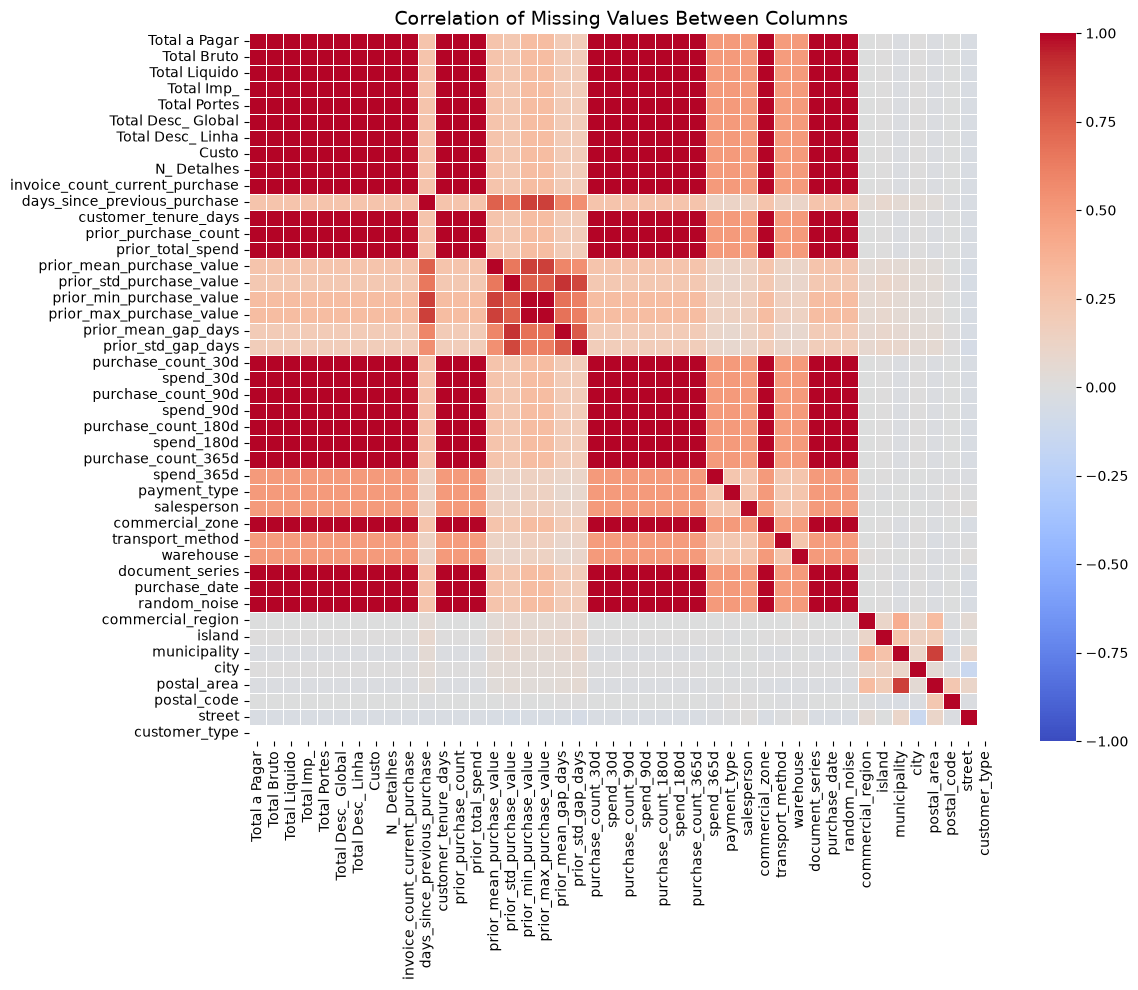

In [26]:
# Correlation of missingness
plt.figure(figsize=(12, 10))
#show only features missing values (non missing features will be meaningless here because they will just leave blank space)
cols_with_missing = fixed_merged.columns[fixed_merged.isna().any()]
missing_corr = fixed_merged[cols_with_missing].isna().corr()


sns.heatmap(missing_corr, annot=False, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation of Missing Values Between Columns", fontsize=14)
plt.tight_layout()
plt.show()

In [27]:
# Drop all rows where 'Total a Pagar' is missing
train = train.dropna(subset=['Total a Pagar'])
print(train.isna().sum())


Total a Pagar                        0
Total Bruto                          0
Total Liquido                        0
Total Imp_                           0
Total Portes                         0
Total Desc_ Global                   0
Total Desc_ Linha                    0
Custo                                0
N_ Detalhes                          0
invoice_count_current_purchase       0
repeat_purchase_90d                  0
days_since_previous_purchase       796
customer_tenure_days                 0
prior_purchase_count                 0
prior_total_spend                    0
prior_mean_purchase_value          797
prior_std_purchase_value          1048
prior_min_purchase_value           603
prior_max_purchase_value           603
prior_mean_gap_days               1243
prior_std_gap_days                1413
purchase_count_30d                   0
spend_30d                            0
purchase_count_90d                   0
spend_90d                            0
purchase_count_180d      

High missingness correlation across 23 features: these values aren't imputable nor synthesizable.

### Removing implausible rows

In [28]:
# Rows where the mean is impossibly greater than the total spend, etc.
corrupted_prior = fixed_train[fixed_train["prior_mean_purchase_value"] > fixed_train["prior_total_spend"]].index

corrupted_spend_365d = fixed_train[fixed_train["spend_365d"] > fixed_train["prior_total_spend"]]["spend_365d"].index
corrupted_purchase_count_180d = fixed_train[fixed_train["spend_180d"] > fixed_train["spend_365d"]]["spend_180d"].index
corrupted_purchase_count_90d = fixed_train[fixed_train["spend_90d"] > fixed_train["spend_180d"]]["spend_90d"].index
corrupted_prior_max_purchase_value = fixed_train[fixed_train["prior_max_purchase_value"] > fixed_train["prior_total_spend"]]["prior_max_purchase_value"].index
corrupted_prior_mean_purchase_value = fixed_train[fixed_train["prior_mean_purchase_value"] < 0]["prior_mean_purchase_value"].index
print(f"Cases Where Spend of 365>total Spend: {corrupted_spend_365d.value_counts().sum()}\nCases where spend180>spend365: {corrupted_purchase_count_180d.value_counts().sum()}\nCases where spend90>spend 180: {corrupted_purchase_count_90d.value_counts().sum()}\nCases where max spend is bigger than total spend: {corrupted_prior_max_purchase_value.value_counts().sum()}\nCases where mean spending is negative: {corrupted_prior_mean_purchase_value.value_counts().sum()}")
# Show all columns to identify the anomaly
pd.set_option('display.max_columns', None)
all_corrupted_index = (
    corrupted_prior.union(corrupted_spend_365d)
    .union(corrupted_purchase_count_180d)
    .union(corrupted_purchase_count_90d)
    .union(corrupted_prior_max_purchase_value)
    .union(corrupted_prior_mean_purchase_value)
    .union(heavy_missing_rows.index)
    .intersection(train.index)  # avoid error from dropping already-dropped rows
)
fixed_train.loc[all_corrupted_index].head(3)

Cases Where Spend of 365>total Spend: 251
Cases where spend180>spend365: 15
Cases where spend90>spend 180: 0
Cases where max spend is bigger than total spend: 116
Cases where mean spending is negative: 16


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
8,962.63,786.27,782.63,180.00,0.0,0.0,3.64,496.926279,46.0,1.0,0,223.0,742.0,8.0,12487.24,1560.905000,1035.729065,130.18,3356.83,74.142857,57.831446,0.0,0.0,0.0,0.00,0.0,0.00,3.0,53906.674517,796571,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 40,Final Excel Warehouse 1,Ctrl Z Series 3,2017-11-11,10000011,-0.519772
14,2460.00,2000.00,2000.00,460.00,0.0,0.0,0.00,0.000000,1.0,1.0,1,49.0,1277.0,31.0,3414.56,-110.147097,124.138784,0.93,552.37,40.933333,51.012462,0.0,0.0,3.0,194.64,6.0,535.93,13.0,1019.820000,239651,Maybe Tomorrow Payment 12,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 22,Final Excel Warehouse 1,Ctrl Z Series 2,2021-09-24,10000018,0.093198
24,2430.26,2404.29,1975.82,454.44,0.0,0.0,428.47,584.657046,65.0,1.0,1,41.0,220.0,6.0,5520.15,920.025000,859.127283,128.78,2456.68,NaN,27.770488,0.0,0.0,2.0,1509.54,4.0,4095.00,6.0,5520.150000,227020,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 40,Final Excel Warehouse 1,Ctrl Z Series 1,2017-11-11,10000031,-0.225723


In [29]:
train = train.drop(index=all_corrupted_index)

### Post-cleaning summary, distributions and outliers

In [30]:
target = "repeat_purchase_90d"
exclude = [target, "customer_id", "ID"]

numerical_cols = (
    train.select_dtypes(include="number")
         .columns.drop(exclude, errors="ignore")
         .tolist()
)

numerical_train = train[numerical_cols]
numerical_summary = numerical_train.describe().T.rename(
    columns={"50%": "median"}
)
numerical_summary["missing"] = numerical_train.isna().sum()
numerical_summary["IQR"] = numerical_summary["75%"] - numerical_summary["25%"]
numerical_summary = numerical_summary[
    ["count", "missing", "mean", "std", "min", "25%", "median", "75%", "max", "IQR"]
]
print(numerical_summary.to_string(float_format=lambda value: f"{value:,.2f}"))

                                  count  missing      mean       std      min      25%   median       75%        max       IQR
Total a Pagar                  5,761.00        0    942.48  1,357.37     0.93   193.16   489.43  1,111.74  22,297.21    918.58
Total Bruto                    5,761.00        0    896.01  1,337.95     0.83   180.00   455.39  1,050.00  21,578.28    870.00
Total Liquido                  5,761.00        0    785.66  1,152.48     0.76   157.45   400.83    915.20  18,127.81    757.75
Total Imp_                     5,761.00        0    156.83    229.71     0.00    31.48    82.79    191.32   4,169.40    159.84
Total Portes                   5,761.00        0      0.98      4.19     0.00     0.00     0.00      0.00     181.06      0.00
Total Desc_ Global             5,761.00        0      0.28      4.21     0.00     0.00     0.00      0.00     184.40      0.00
Total Desc_ Linha              5,761.00        0    110.07    284.13     0.00     0.00    12.67     90.84   4,1

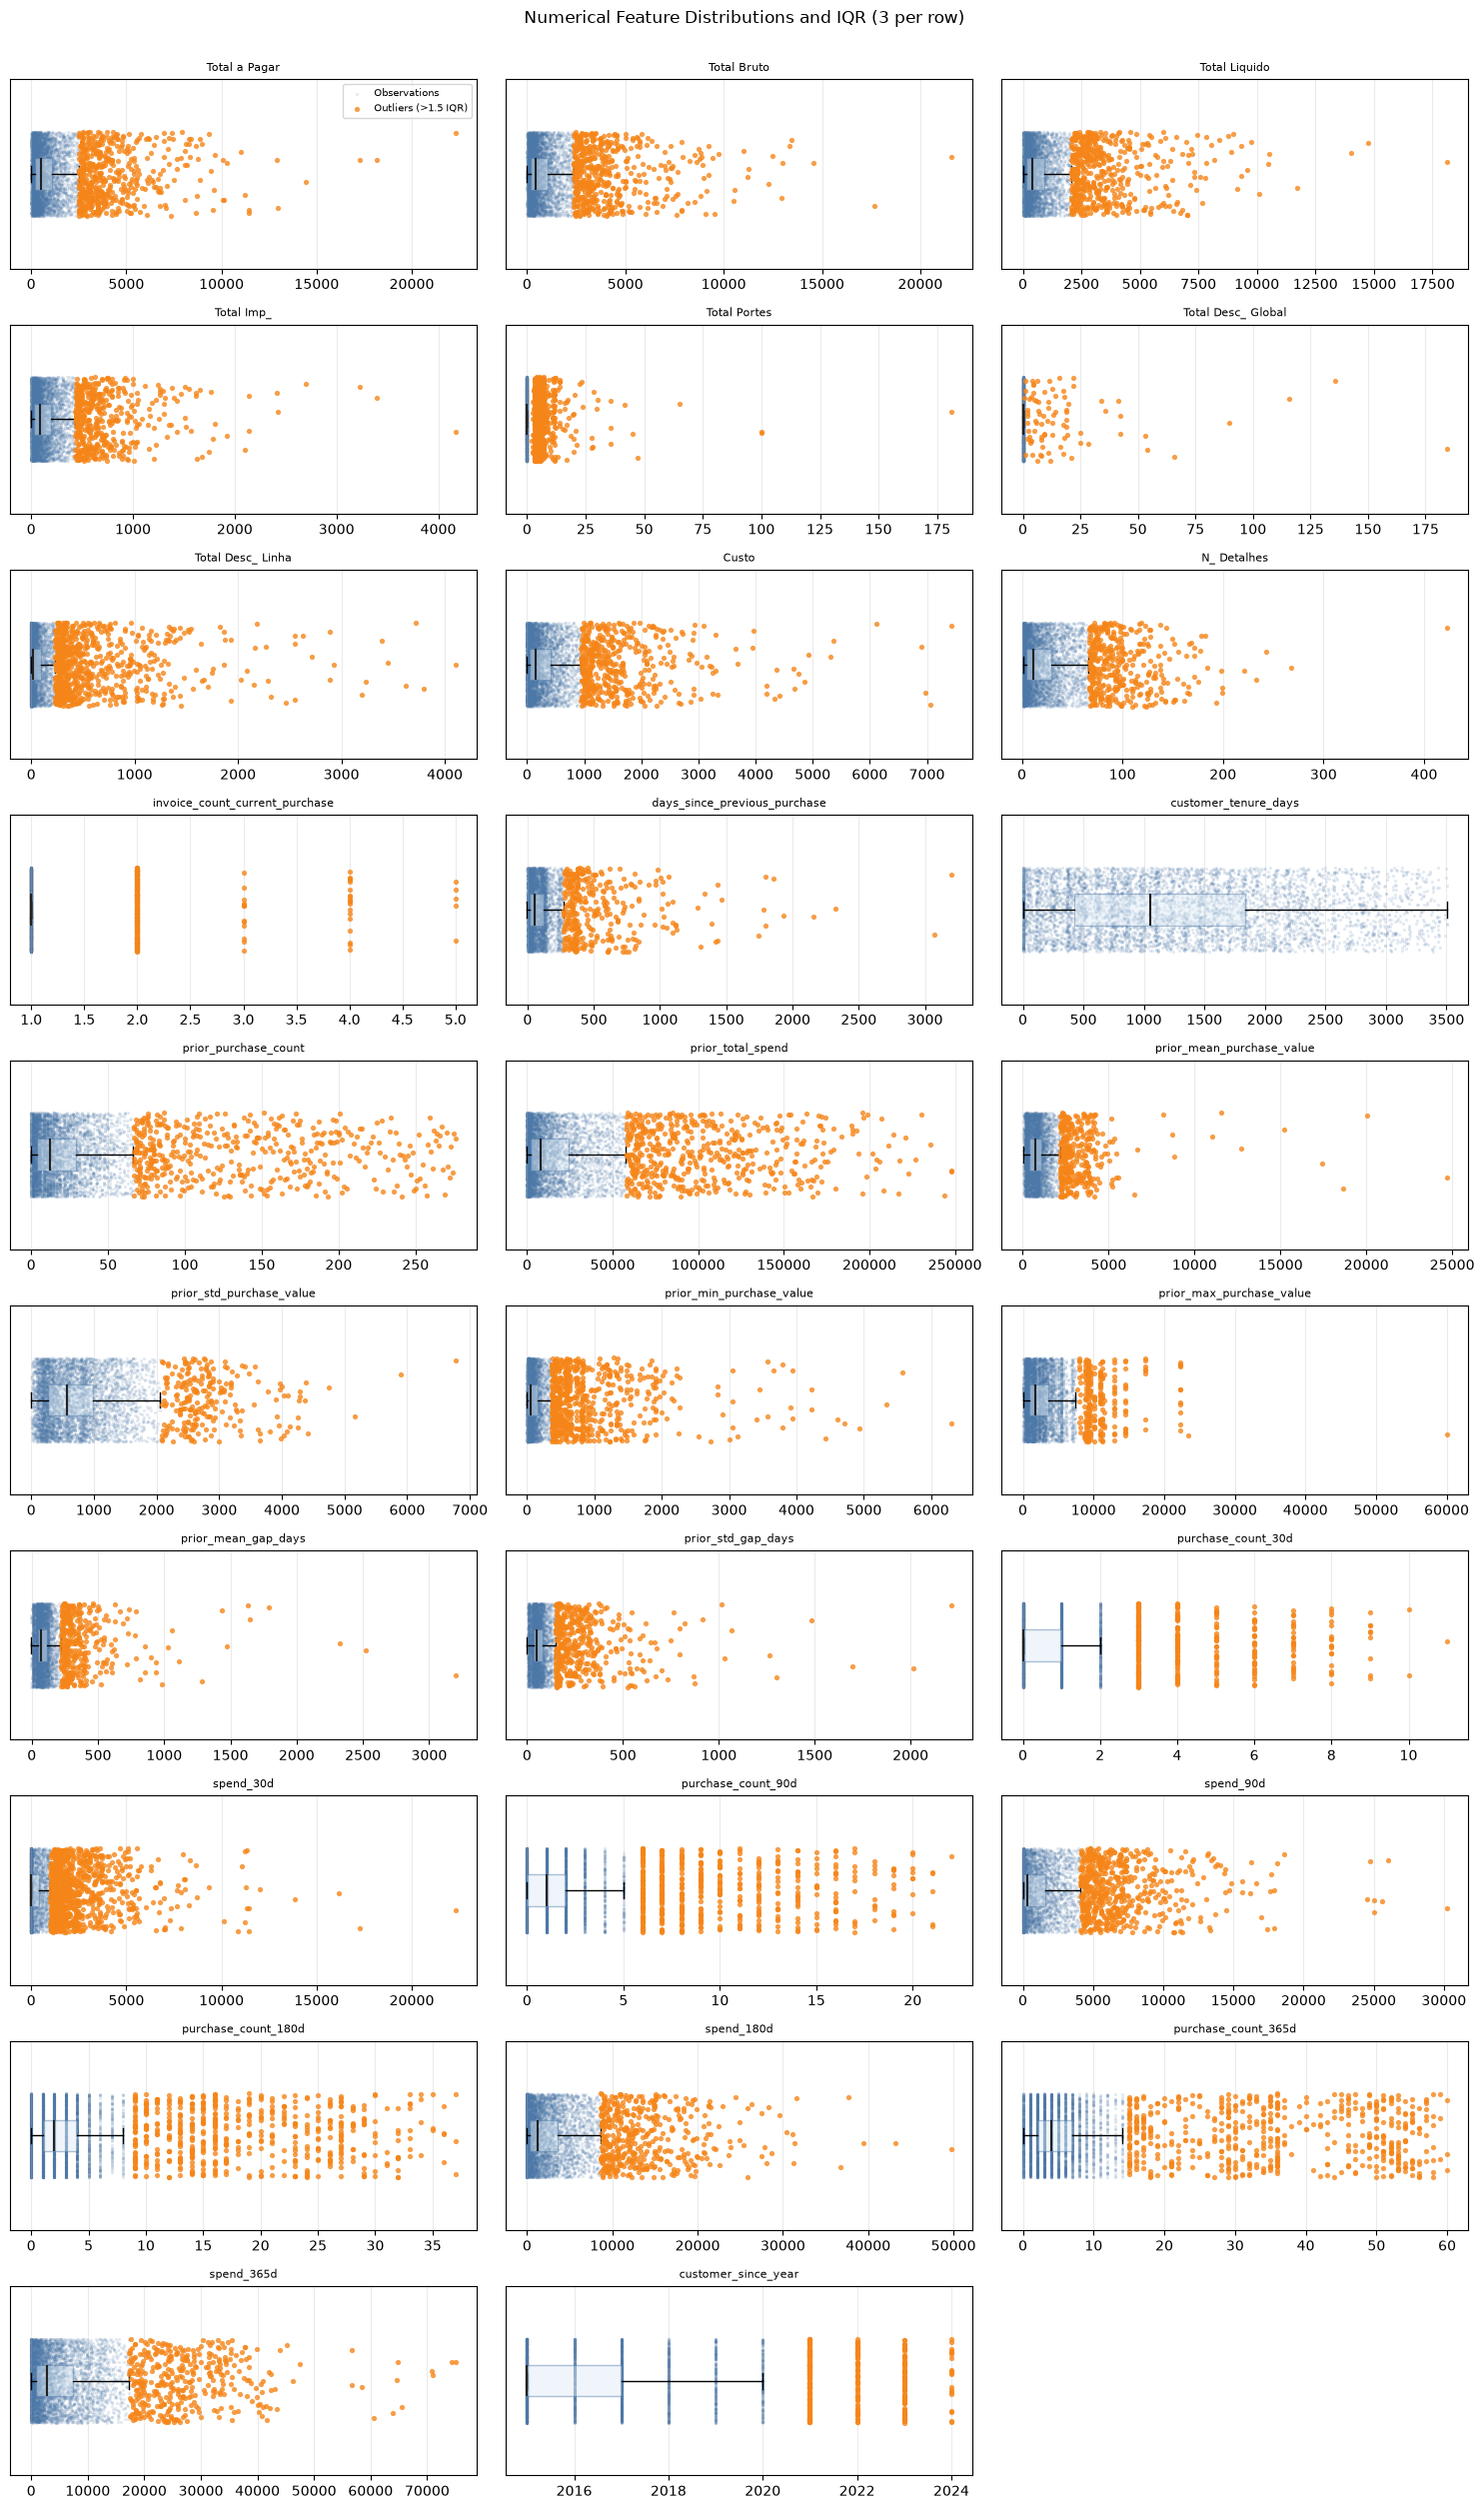

In [31]:
plot_columns = 3
plot_rows = (len(numerical_cols) + plot_columns - 1) // plot_columns
fig, axes = plt.subplots(
    plot_rows, plot_columns,
    figsize=(15, plot_rows * 2.5),
    squeeze=False,
)
rng = np.random.default_rng(42)

for feature_index, (ax, feature) in enumerate(zip(axes.flat, numerical_cols)):
    values = numerical_train[feature].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_mask = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
    jitter = rng.uniform(-0.2, 0.2, size=len(values))

    ax.boxplot(
        values,
        positions=[1],
        orientation="horizontal",
        showfliers=False,
        patch_artist=True,
        boxprops={"facecolor": "#DCEAF4", "edgecolor": "#4C78A8", "alpha": 0.45},
        medianprops={"color": "#222222", "linewidth": 1.5},
    )
    ax.scatter(
        values[~outlier_mask], 1 + jitter[~outlier_mask],
        s=5, alpha=0.16, color="#4C78A8", linewidths=0,
        label="Observations" if feature_index == 0 else None,
        rasterized=True,
    )
    ax.scatter(
        values[outlier_mask], 1 + jitter[outlier_mask],
        s=14, alpha=0.8, color="#F58518", linewidths=0,
        label="Outliers (>1.5 IQR)" if feature_index == 0 else None,
        zorder=3,
    )
    ax.set_title(feature, fontsize=8)
    ax.set_yticks([])
    ax.set_ylim(0.55, 1.45)
    ax.grid(axis="x", alpha=0.25)

for ax in axes.flat[len(numerical_cols):]:
    ax.set_visible(False)

axes.flat[0].legend(loc="upper right", fontsize=7)
fig.suptitle("Numerical Feature Distributions and IQR (3 per row)", y=1.002)
fig.tight_layout()
plt.show()

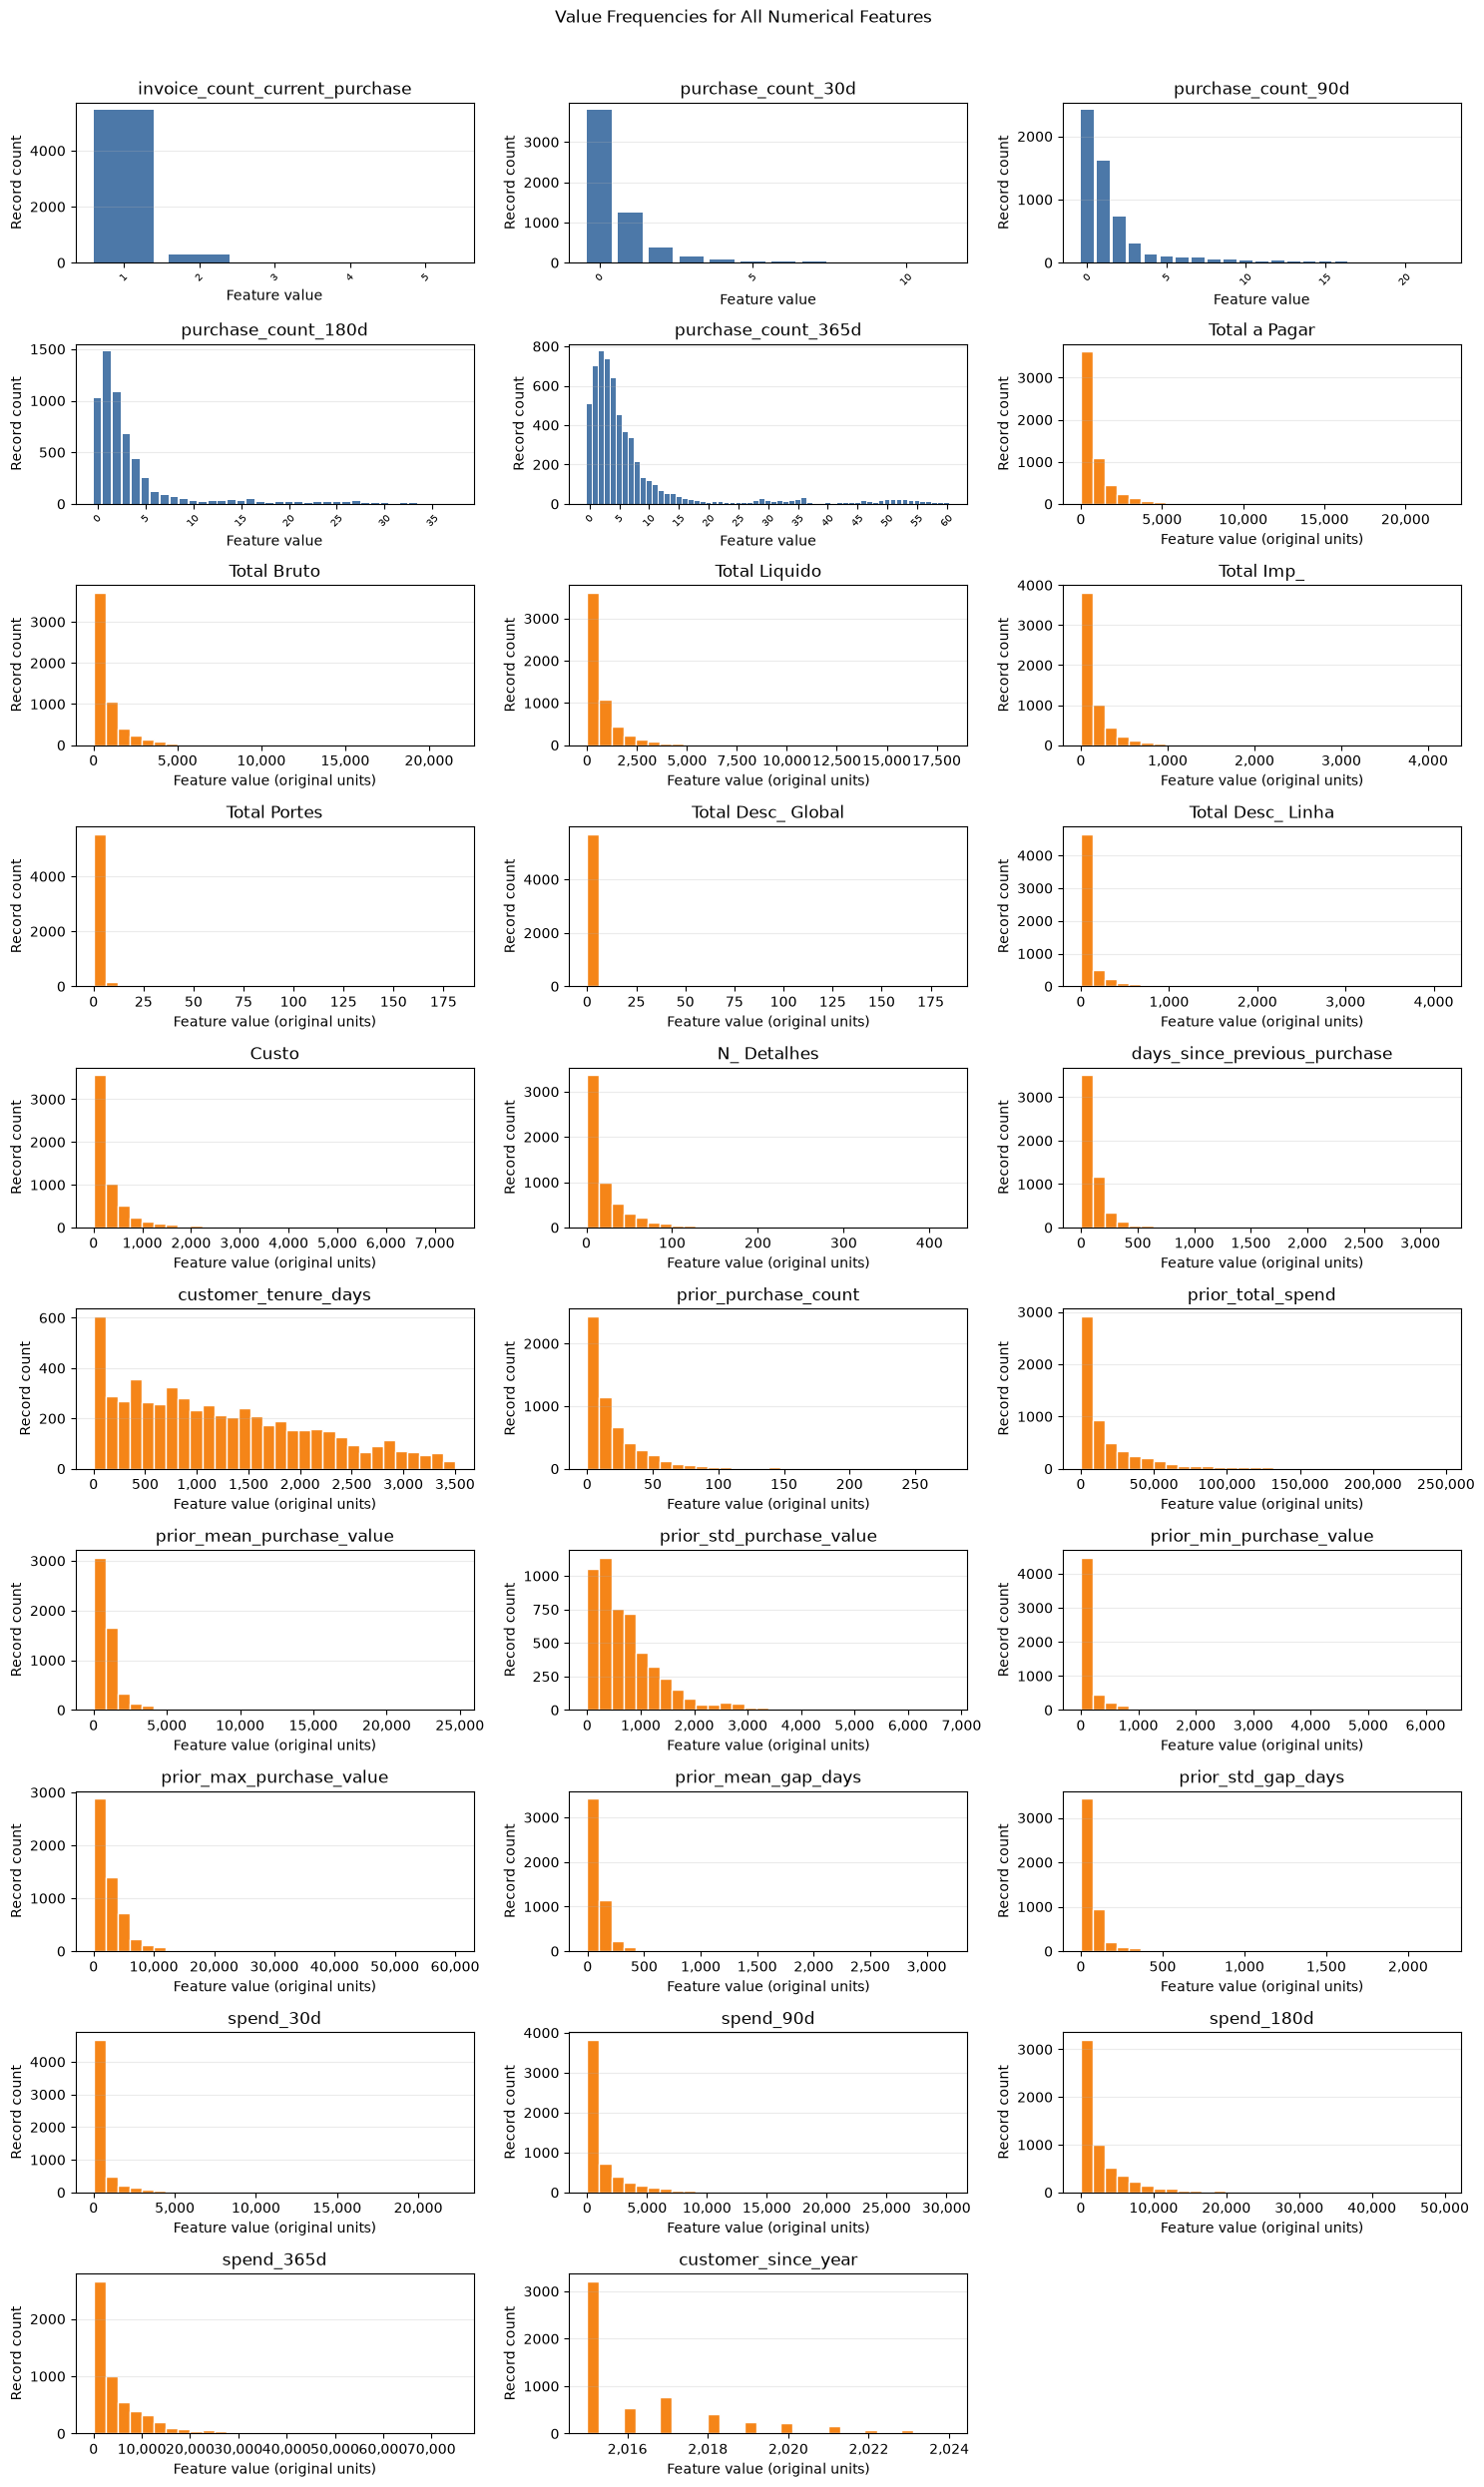

In [32]:
frequency_features = [
    feature for feature in numerical_cols
    if feature.startswith("purchase_count_")
    or feature == "invoice_count_current_purchase"
]
continuous_features = [
    feature for feature in numerical_cols if feature not in frequency_features
]
plot_features = frequency_features + continuous_features
plot_columns = 3
plot_rows = (len(plot_features) + plot_columns - 1) // plot_columns
fig, axes = plt.subplots(
    plot_rows, plot_columns,
    figsize=(15, plot_rows * 2.5),
    squeeze=False,
)

# Discrete purchase counts: one bar per observed value.
for ax, feature in zip(axes.flat, frequency_features):
    counts = numerical_train[feature].value_counts().sort_index()
    ax.bar(counts.index, counts.values, color="#4C78A8")
    ax.set_title(feature)
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Record count")
    ax.set_xticks(counts.index[::5] if feature.startswith("purchase_count_") else counts.index)
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
    ax.grid(axis="y", alpha=0.25)

# Other numerical features: histogram bins show the number of records per range.
for ax, feature in zip(axes.flat[len(frequency_features):], continuous_features):
    values = numerical_train[feature].dropna()
    ax.hist(values, bins=30, color="#F58518", edgecolor="white")
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.set_title(feature)
    ax.set_xlabel("Feature value (original units)")
    ax.set_ylabel("Record count")
    ax.grid(axis="y", alpha=0.25)

for ax in axes.flat[len(plot_features):]:
    ax.set_visible(False)

fig.suptitle("Value Frequencies for All Numerical Features", y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()

**Potential data-quality issue:** some purchase-history fields contain extreme values, including values near €1 billion. These could be data-entry or processing errors and can distort summaries and model fitting. Since the target is repeat purchase within 90 days, the model should learn typical customer behavior rather than be driven by a handful of implausible records. Investigate these rows and verify their source before deciding whether to correct or exclude them.

In [33]:
outlier_counts = {}
for feature in numerical_cols:
    values = numerical_train[feature].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_mask = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
    outlier_counts[feature] = int(outlier_mask.sum())

outlier_counts = pd.Series(outlier_counts, name="outlier_count").sort_values(
    ascending=False, kind="stable"
)
print(outlier_counts.to_string())

spend_30d                         870
Total Portes                      852
Total Desc_ Linha                 726
prior_min_purchase_value          643
spend_90d                         568
purchase_count_365d               544
purchase_count_180d               543
Total Liquido                     520
prior_total_spend                 515
Total a Pagar                     514
Total Bruto                       506
Custo                             476
Total Imp_                        474
purchase_count_90d                468
prior_purchase_count              457
spend_180d                        449
prior_std_gap_days                440
N_ Detalhes                       392
spend_365d                        386
purchase_count_30d                368
prior_mean_gap_days               357
days_since_previous_purchase      353
prior_mean_purchase_value         344
customer_since_year               338
invoice_count_current_purchase    320
prior_max_purchase_value          253
prior_std_pu

## II.2 Imputation of remaining missing values
====missing work here=====
### **Unimputable Features**
(Rows with missing values were dropped above; no imputation fitted yet. Any imputation must be fit on the training fold only.)
Imputations for many of the features is extremely difficult, because many features are very interdependant and modifying a feature requires further modifications for all related features to avoid noise.

Ex:

Total a Pagar \& prior_mean_purchase_value \& prior_std_purchase_value

days_since_previous_purchase \& prior_mean_gap_days & prior_std_gap_days


### **Imputable Features**
Some features however can be imputable, for example, deriving the country or region using the city or postal code etc.

In [34]:
# 1. Display missing counts before imputation
cols_to_check = ['city', 'municipality', 'postal_area', 'country_or_region']
print("--- Missing Values BEFORE ---")
print(train[cols_to_check].isna().sum())
print("\n")

# 2. Define the imputation function
def impute_geography_from_peers(df):
    df_clean = df.copy()
    
    # Define mapping relationships (source_column -> target_column_to_fill)
    mapping_pairs = [
        # --- 1. Fill highly specific locations first ---
        ('postal_area', 'city'),               # if city is missing but both share the same postal_area, impute to the same city
        
        # --- 2. Fill intermediate administrative zones using the (now more complete) cities ---
        ('city', 'municipality'),              # if municipality is missing but both share the same city, impute to the same municipality
        ('postal_area', 'municipality'),       # if municipality is missing but both share the same postal_area, impute to the same municipality
        
        # --- 3. Fill the broadest regions last, leveraging all the newly filled granular data ---
        ('city', 'country_or_region'),         # if country is missing but both share the same city, impute to the same country
        ('postal_area', 'country_or_region'),  # if country is missing but both share the same postal_area, impute to the same country
        ('municipality', 'country_or_region')  # if country is missing but both share the same municipality, impute to the same country
    ]
    
    for source_col, target_col in mapping_pairs:
        if source_col not in df_clean.columns or target_col not in df_clean.columns:
            continue
            
        missing_target = df_clean[target_col].isna()
        has_source = df_clean[source_col].notna()
        rows_to_fill = missing_target & has_source
        
        if not rows_to_fill.any():
            continue
            
        # Create lookup dictionary from rows where both columns are populated
        reference_data = df_clean.dropna(subset=[source_col, target_col])
        lookup_dict = reference_data.groupby(source_col)[target_col].first().to_dict()
        
        # Map the learned values to the missing rows
        df_clean.loc[rows_to_fill, target_col] = df_clean.loc[rows_to_fill, source_col].map(lookup_dict)
        
    return df_clean

# 3. Apply the function to the dataframe
train = impute_geography_from_peers(train)

# 4. Display missing counts after imputation to verify
print("--- Missing Values AFTER ---")
print(f"{train[cols_to_check].isna().sum()}\n if values are the same, restart the notebook")


--- Missing Values BEFORE ---
city                 1797
municipality          151
postal_area           210
country_or_region       0
dtype: int64


--- Missing Values AFTER ---
city                 282
municipality         151
postal_area          210
country_or_region      0
dtype: int64
 if values are the same, restart the notebook


Even tho we have fixed Country_or_region Feature, its value imbalance is too high to give us meaning

In [35]:
train[train["city"].isna()][cols_to_check]

,city,municipality,postal_area,country_or_region
28,NaN,Municipality MU122: Council of Last Minute Edits,Postal area PA236: Hidden Sheet Sector,Country CT10: Land of The Final Version
46,NaN,Municipality MU31: Council of Last Minute Edits,Postal area PA121: Hidden Sheet Sector,Country CT10: Land of The Final Version
136,NaN,Municipality MU105: Council of Last Minute Edits,Postal area PA30: Hidden Sheet Sector,Country CT10: Land of The Final Version
153,NaN,Municipality MU31: Council of Last Minute Edits,Postal area PA121: Hidden Sheet Sector,Country CT10: Land of The Final Version
157,NaN,Municipality MU31: Council of Last Minute Edits,Postal area PA121: Hidden Sheet Sector,Country CT10: Land of The Final Version
...,...,...,...,...
6380,NaN,Municipality MU31: Council of Last Minute Edits,Postal area PA121: Hidden Sheet Sector,Country CT10: Land of The Final Version
6414,NaN,NaN,NaN,Country CT5: Land of The Final Version
6453,NaN,Municipality MU31: Council of Last Minute Edits,Postal area PA121: Hidden Sheet Sector,Country CT10: Land of The Final Version
6466,NaN,NaN,NaN,Country CT5: Land of The Final Version


## II.3 Categorical Encoding
Encode payment, salesperson, zone, transport, and warehouse.

====missing work here=====

## II.4 Feature Engineering
Derive new temporal or interaction features from purchase dates, historical gaps, and the random noise field.

====missing work here=====

## II.5 Scaling & Leakage Prevention
Fit all preprocessing (scaling, imputation, encoding) strictly on the training fold and apply to validation/test sets.

====missing work here=====

---
# III. Feature Selection Execution
## III.1 Filter Methods (Statistical Evaluation)
### Numerical vs. Numerical: Spearman (monotonic)
Checks monotonic correlation between features and with the label.

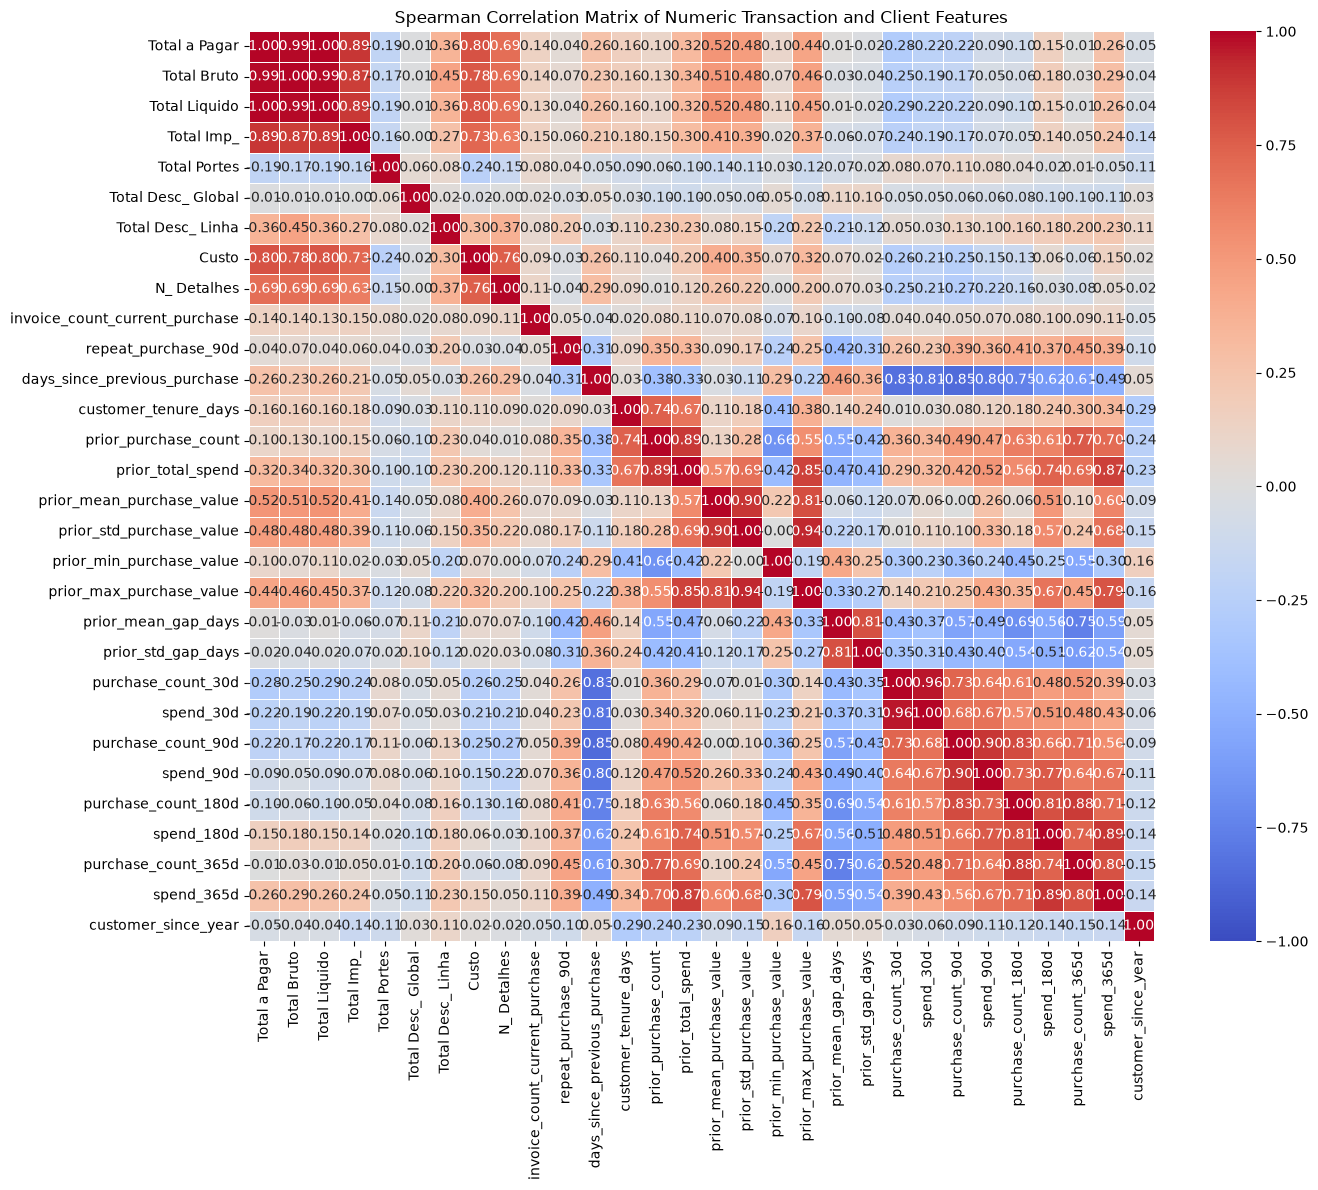

repeat_purchase_90d               1.000000
purchase_count_365d               0.446338
purchase_count_180d               0.410404
purchase_count_90d                0.394268
spend_365d                        0.394229
spend_180d                        0.371373
spend_90d                         0.358836
prior_purchase_count              0.347499
prior_total_spend                 0.330962
purchase_count_30d                0.258164
prior_max_purchase_value          0.254061
spend_30d                         0.231644
Total Desc_ Linha                 0.201404
prior_std_purchase_value          0.168845
customer_tenure_days              0.094635
prior_mean_purchase_value         0.090791
Total Bruto                       0.068460
Total Imp_                        0.060357
invoice_count_current_purchase    0.045006
Total Portes                      0.041563
Total a Pagar                     0.041126
Total Liquido                     0.038605
Custo                            -0.026259
Total Desc_

In [36]:
numeric_features = train.select_dtypes(include="number")
numeric_features = numeric_features.loc[
    :, numeric_features.nunique(dropna=True) > 1
]
corr_matrix = numeric_features.corr(method='spearman')

plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Spearman Correlation Matrix of Numeric Transaction and Client Features")
plt.tight_layout()
plt.show()

print(corr_matrix["repeat_purchase_90d"].sort_values(ascending=False))

### Numerical vs. Numerical: Pearson (linear)

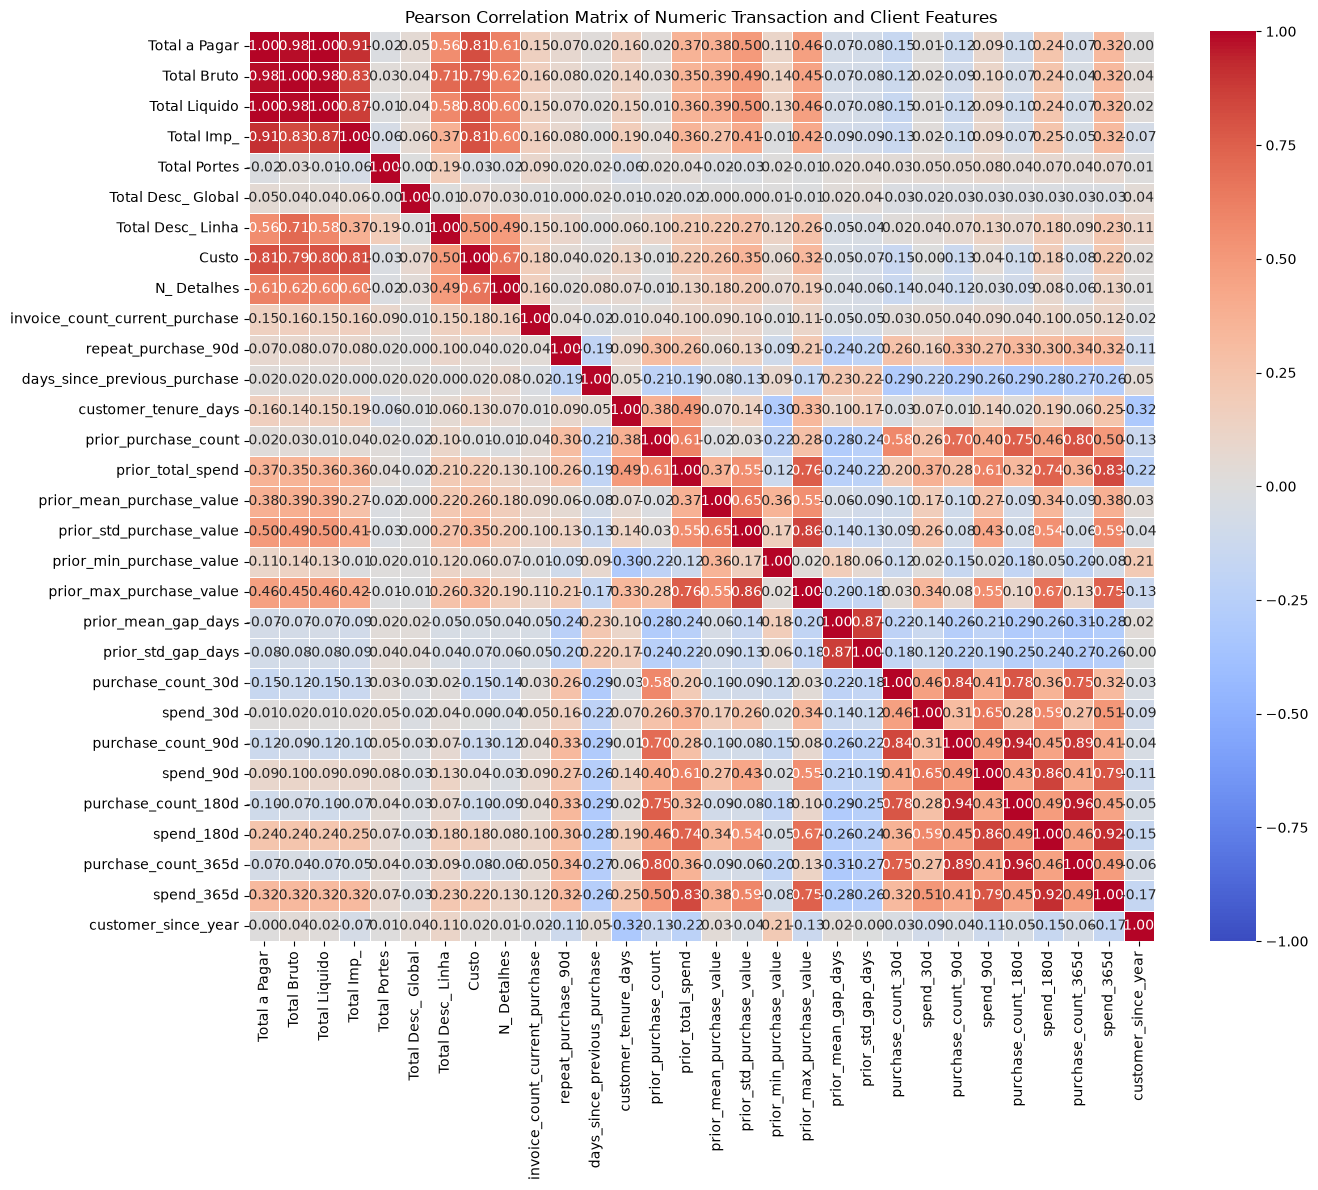

repeat_purchase_90d               1.000000
purchase_count_365d               0.339360
purchase_count_180d               0.332380
purchase_count_90d                0.326169
spend_365d                        0.319138
prior_purchase_count              0.298867
spend_180d                        0.298486
spend_90d                         0.265575
prior_total_spend                 0.259665
purchase_count_30d                0.259290
prior_max_purchase_value          0.205250
spend_30d                         0.163253
prior_std_purchase_value          0.133156
Total Desc_ Linha                 0.100991
customer_tenure_days              0.088169
Total Imp_                        0.080889
Total Bruto                       0.079932
Total a Pagar                     0.071329
Total Liquido                     0.067887
prior_mean_purchase_value         0.061228
Custo                             0.042502
invoice_count_current_purchase    0.037700
N_ Detalhes                       0.019621
Total Porte

In [37]:
corr_matrix = numeric_features.corr(method="pearson")
plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Pearson Correlation Matrix of Numeric Transaction and Client Features")
plt.tight_layout()
plt.show()

print(corr_matrix["repeat_purchase_90d"].sort_values(ascending=False))

Indications show some features have no correlation to any feature nor the label in both test including pearson and spearman, this gives insights on the first features to be discarded

### Numerical vs. Categorical: ANOVA
====missing work here=====

### Categorical vs. Categorical: Chi-Squared and Mutual Information / MIC
====missing work here=====

## III.2 Wrapper Methods (Search Optimization)
Recursive Feature Elimination (RFE), wrapped inside a 10-fold cross-validation loop to prevent selection bias.

====missing work here=====

## III.3 Embedded Methods (Penalization)
LASSO (L1) and Ridge (L2) regularization.

====missing work here=====

## III.4 Exclusions
Identifier-like variables (`ID`, `customer_id`) and `random_noise` were removed in Section II.1 (`columns_to_drop`), along with `customer_type` and `street` for excessive missingness. `commercial_zone` and `warehouse` are flagged as candidates for removal (near-constant).

====missing work here===== (final decision on `commercial_zone` / `warehouse`)

---
# IV. Model Selection & Assessment Strategy
## IV.1 Candidate Generation

Lean setup: the cleaned columns as they are, plus two date features. Extra engineered features are only added if a quick test shows they help.

- **Dropped:** `postal_code`, `address`, `company_name` (near-unique text, the trees would memorize them)
- **Added:** `purchase_month`, `days_since_first_purchase`
- **Categoricals:** rare levels merged, NaN kept as its own level
- **Numeric NaN:** left as is (XGBoost and HistGradientBoosting handle it natively)
- **Models:** XGBoost, HistGradientBoosting, and the average of the two

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit, cross_val_predict
from sklearn.metrics import roc_auc_score, f1_score, precision_recall_curve, classification_report
from sklearn.inspection import permutation_importance
from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier

TARGET = "repeat_purchase_90d"


def prepare_features(df):
    d = df.copy()

    # two date features
    d["purchase_date"] = pd.to_datetime(d["purchase_date"], errors="coerce")
    d["purchase_month"] = d["purchase_date"].dt.month
    d["days_since_first_purchase"] = (d["purchase_date"] - d["purchase_date"].min()).dt.days

    # near-unique text columns
    d = d.drop(columns=["purchase_date", "postal_code", "address", "company_name"], errors="ignore")

    # categoricals: NaN -> "missing", rare levels -> "rare"
    for c in d.select_dtypes(include=["object", "string"]).columns:
        s = d[c].astype(object).fillna("missing")
        rare = s.value_counts()[lambda v: v < 30].index
        d[c] = s.where(~s.isin(rare), "rare").astype("category")
    return d


data = prepare_features(train)
y = data[TARGET]

# `train` no longer has customer_id but keeps its index -> recover it so the same
# customer is never in both the training and validation fold.
groups = fixed_train.loc[data.index, "customer_id"].values

xgb_params = dict(n_estimators=766, learning_rate=0.022, max_depth=6, min_child_weight=3,
                  subsample=0.94, colsample_bytree=0.66, reg_alpha=8.9, reg_lambda=6.2,
                  enable_categorical=True, tree_method="hist", n_jobs=-1)
hgb_params = dict(learning_rate=0.03, max_iter=400, max_leaf_nodes=15, min_samples_leaf=40,
                  l2_regularization=5, categorical_features="from_dtype")

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

X = data.drop(columns=TARGET)
print(f"{X.shape[1]} features, {len(X)} rows")

43 features, 5761 rows


### Do any extra features earn their place?
Each block is added on its own and kept only if out-of-fold ROC-AUC rises by at least 0.002 (same rule as the final pipeline). With the default 0.002 cutoff, small gains can still be noise, so treat borderline results with caution.

In [39]:
def add_windows(d):
    """Cumulative windows -> non-overlapping windows."""
    d = d.copy()
    for p in ["spend", "purchase_count"]:
        d[f"{p}_31_90d"] = d[f"{p}_90d"] - d[f"{p}_30d"]
        d[f"{p}_91_180d"] = d[f"{p}_180d"] - d[f"{p}_90d"]
        d[f"{p}_181_365d"] = d[f"{p}_365d"] - d[f"{p}_180d"]
        d = d.drop(columns=[f"{p}_90d", f"{p}_180d", f"{p}_365d"])
    return d


def add_ratios(d):
    """Average order value and spend momentum (NaN when the denominator is 0)."""
    d = d.copy()
    d["aov_30d"] = d["spend_30d"] / d["purchase_count_30d"].replace(0, np.nan)
    d["aov_prior"] = d["prior_total_spend"] / d["prior_purchase_count"].replace(0, np.nan)
    d["spend_velocity"] = d["spend_30d"] / (d["spend_90d"] - d["spend_30d"]).replace(0, np.nan)
    return d.replace([np.inf, -np.inf], np.nan)


def quick_auc(features):
    prob = cross_val_predict(XGBClassifier(**xgb_params, random_state=0), features, y,
                             cv=cv, groups=groups, method="predict_proba")[:, 1]
    return roc_auc_score(y, prob)


X_base = X
base_auc = quick_auc(X_base)
print(f"base features: AUC {base_auc:.4f}")

# ratios first: they read the cumulative columns that add_windows later removes
blocks = {"ratios": add_ratios, "windows": add_windows}
kept = []
for name, fn in blocks.items():
    gain = quick_auc(fn(X_base)) - base_auc
    keep = gain >= 0.002
    print(f"  + {name:<8} {gain:+.4f}  {'KEEP' if keep else 'skip'}")
    if keep:
        kept.append(name)

X = X_base
for name in kept:
    X = blocks[name](X)

print(f"\nfinal feature count: {X.shape[1]}")

base features: AUC 0.7963
  + ratios   -0.0004  skip
  + windows  +0.0008  skip

final feature count: 43


### Compare the models
Scores are out-of-fold (5 folds, grouped by customer). The F1-optimal threshold is picked on those same predictions.

In [40]:
def best_f1_threshold(y_true, prob):
    prec, rec, thr = precision_recall_curve(y_true, prob)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    i = np.argmax(f1[:-1])
    return thr[i], f1[i]


models = {
    "XGBoost": XGBClassifier(**xgb_params, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(**hgb_params, random_state=42),
}

oof = {name: cross_val_predict(m, X, y, cv=cv, groups=groups, method="predict_proba")[:, 1]
       for name, m in models.items()}
oof["Average (XGB + HGB)"] = (oof["XGBoost"] + oof["HistGradientBoosting"]) / 2

rows = []
for name, prob in oof.items():
    thr, f1_best = best_f1_threshold(y, prob)
    rows.append({"Model": name, "ROC-AUC": roc_auc_score(y, prob),
                 "F1 @ 0.50": f1_score(y, prob >= 0.5), "Best F1": f1_best, "Threshold": thr})

results = pd.DataFrame(rows).sort_values("Best F1", ascending=False).reset_index(drop=True)
print(f"predict-all-1 baseline F1: {2 * y.mean() / (1 + y.mean()):.4f}\n")
print(results.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

predict-all-1 baseline F1: 0.7292

               Model  ROC-AUC  F1 @ 0.50  Best F1  Threshold
             XGBoost   0.7958     0.7550   0.7714     0.3604
 Average (XGB + HGB)   0.7934     0.7488   0.7695     0.3505
HistGradientBoosting   0.7759     0.7251   0.7594     0.2780


### Best model: threshold and report

Best model: XGBoost (threshold 0.360)

              precision    recall  f1-score   support

           0       0.73      0.51      0.60      2455
           1       0.70      0.86      0.77      3306

    accuracy                           0.71      5761
   macro avg       0.71      0.68      0.68      5761
weighted avg       0.71      0.71      0.70      5761



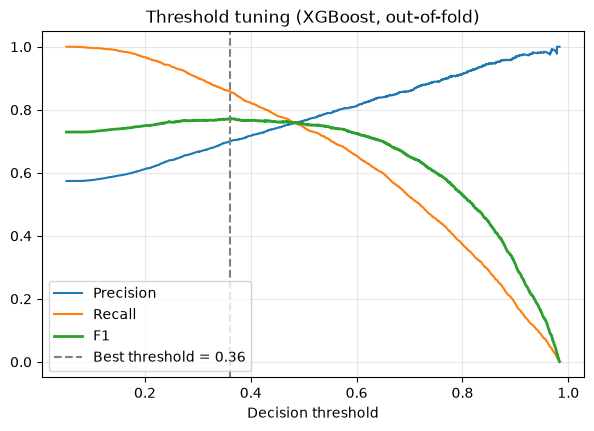

In [41]:
best_name = results.loc[0, "Model"]
best_threshold = results.loc[0, "Threshold"]
best_prob = oof[best_name]

print(f"Best model: {best_name} (threshold {best_threshold:.3f})\n")
print(classification_report(y, (best_prob >= best_threshold).astype(int)))

prec, rec, thr = precision_recall_curve(y, best_prob)
f1 = 2 * prec * rec / (prec + rec + 1e-12)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(thr, prec[:-1], label="Precision")
ax.plot(thr, rec[:-1], label="Recall")
ax.plot(thr, f1[:-1], label="F1", linewidth=2)
ax.axvline(best_threshold, color="grey", linestyle="--", label=f"Best threshold = {best_threshold:.2f}")
ax.set_title(f"Threshold tuning ({best_name}, out-of-fold)")
ax.set_xlabel("Decision threshold")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### Which features matter
Features with importance of 0 or below can be dropped.

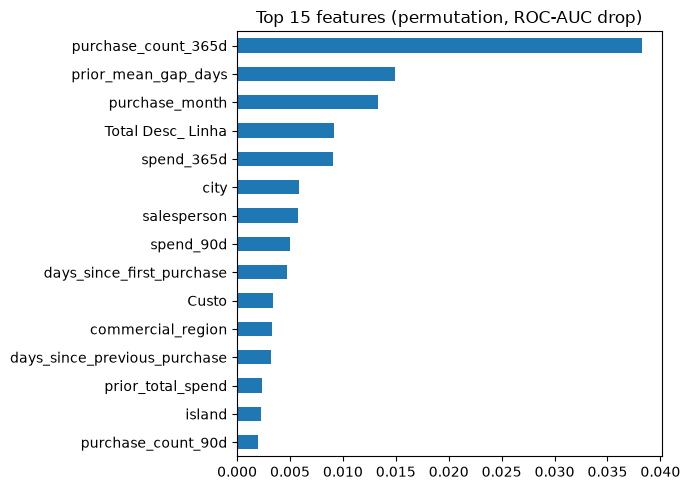

Importance <= 0: ['invoice_count_current_purchase', 'warehouse', 'payment_type', 'Total Desc_ Global', 'country_or_region', 'purchase_count_30d', 'prior_purchase_count', 'Total a Pagar', 'Total Liquido', 'Total Portes', 'Total Imp_', 'document_series', 'municipality', 'prior_std_purchase_value', 'customer_tenure_days', 'customer_since_year', 'Total Bruto', 'purchase_count_180d', 'prior_max_purchase_value', 'prior_min_purchase_value', 'postal_area', 'prior_mean_purchase_value', 'transport_method']


In [42]:
# Permutation importance of XGBoost on a held-out 20% (grouped by customer).
tr_idx, va_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
                      .split(X, y, groups))

xgb_model = XGBClassifier(**xgb_params, random_state=42).fit(X.iloc[tr_idx], y.iloc[tr_idx])
perm = permutation_importance(xgb_model, X.iloc[va_idx], y.iloc[va_idx], scoring="roc_auc",
                              n_repeats=10, random_state=42, n_jobs=-1)

importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)

importance.head(15)[::-1].plot.barh(figsize=(7, 5), title="Top 15 features (permutation, ROC-AUC drop)")
plt.tight_layout()
plt.show()

print("Importance <= 0:", importance[importance <= 0].index.tolist())

## IV.2 Resampling Method
Stratified 10-fold CV; nested CV if tuning hyperparameters.

====missing work here=====

## IV.3 Classification Metrics
Precision, Recall, F1, Balanced Accuracy, ROC-AUC, PR-AUC.

====missing work here=====

## IV.4 Threshold Tuning
Precision-Recall curves to choose the probability cutoff.

====missing work here=====

## IV.5 Statistical Significance
Paired / resampled t-test on CV folds, or McNemar's test on a single hold-out.

====missing work here=====

---
# V. Final Output & Deliverables
## V.1 Kaggle Submission
Predictions for the 986 observations in `test.csv`, without altering the ID column, formatted identically to `sample_submission.csv`.

====missing work here=====

## V.2 Deliverable 2: 2-page PDF
Pipeline schematic plus justification of feature selection, evaluation metrics, and preprocessing.

====missing work here=====

In [43]:
"""Repeat-purchase (90d) pipeline: one file, ~100 lines.

What it does
  1. Builds features on train+test together (same code, no rows dropped).
  2. Validates with StratifiedGroupKFold on customer_id (honest estimate).
  3. Averages XGBoost + HistGradientBoosting over a few seeds.
  4. Picks the F1-optimal threshold on out-of-fold predictions.
  5. Writes submission.csv.
"""
import os
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from xgboost import XGBClassifier

DATA_DIR = os.environ.get("DATA_DIR", "../data")
TARGET = "repeat_purchase_90d"
SEEDS = [0, 1, 2]
# Uses the date of the customer's NEXT row in train+test. Strong, but it peeks at
# "the future" -> only switch on if your assignment rules allow it.
USE_NEXT_ROW = False

# ---------------------------------------------------------------- load
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
clients = pd.read_csv(f"{DATA_DIR}/clientes.csv")

n_train = len(train)
df = pd.concat([train, test], ignore_index=True).merge(
    clients, on="customer_id", how="left", validate="many_to_one")


# ---------------------------------------------------------------- features
def build_features(d):
    d = d.copy()
    num = d.select_dtypes("number").columns.drop([TARGET, "ID", "customer_id"], errors="ignore")
    d["n_missing"] = d[num].isna().sum(axis=1)          # "no history" rows miss many columns together

    # dates
    d["purchase_date"] = pd.to_datetime(d["purchase_date"], errors="coerce")
    d["month"] = d["purchase_date"].dt.month
    d["dow"] = d["purchase_date"].dt.dayofweek
    d["day_idx"] = (d["purchase_date"] - d["purchase_date"].min()).dt.days
    d["days_to_end"] = d["day_idx"].max() - d["day_idx"]  # label is cut off near the end of the data

    # cumulative windows -> non-overlapping windows
    for p in ["spend", "purchase_count"]:
        d[f"{p}_31_90d"] = d[f"{p}_90d"] - d[f"{p}_30d"]
        d[f"{p}_91_180d"] = d[f"{p}_180d"] - d[f"{p}_90d"]
        d[f"{p}_181_365d"] = d[f"{p}_365d"] - d[f"{p}_180d"]
        d = d.drop(columns=[f"{p}_90d", f"{p}_180d", f"{p}_365d"])

    # ratios (NaN when the denominator is 0; trees handle NaN natively)
    d["aov_30d"] = d["spend_30d"] / d["purchase_count_30d"].replace(0, np.nan)
    d["aov_prior"] = d["prior_total_spend"] / d["prior_purchase_count"].replace(0, np.nan)
    d["spend_velocity"] = d["spend_30d"] / d["spend_31_90d"].replace(0, np.nan)
    d["gap_ratio"] = d["days_since_previous_purchase"] / d["prior_mean_gap_days"].replace(0, np.nan)

    # customer features from train+test rows (no labels used)
    ordered = d.sort_values("purchase_date").groupby("customer_id")["purchase_date"]
    d["cust_rows"] = d.groupby("customer_id")["purchase_date"].transform("size")
    d["days_since_prev_row"] = ordered.diff().dt.days
    if USE_NEXT_ROW:
        d["days_to_next_row"] = -ordered.diff(-1).dt.days

    # categoricals: rare levels merged, NaN kept as its own level
    drop = ["ID", "customer_id", "random_noise", "customer_type", "street", "address",
            "postal_code", "company_name", "commercial_zone", "warehouse", "purchase_date", TARGET]
    d = d.drop(columns=drop, errors="ignore")
    for c in d.select_dtypes(include=["object", "string"]).columns:
        s = d[c].astype(object)
        rare = s.value_counts()[lambda v: v < 30].index
        d[c] = s.where(~s.isin(rare), "rare").fillna("missing").astype("category")
    return d


X_all = build_features(df)
X, X_test = X_all.iloc[:n_train], X_all.iloc[n_train:]
y = train[TARGET].reset_index(drop=True)
groups = train["customer_id"].values


def models(seed):
    return [
        XGBClassifier(n_estimators=766, learning_rate=0.022, max_depth=6, min_child_weight=3,
                      subsample=0.94, colsample_bytree=0.66, reg_alpha=8.9, reg_lambda=6.2,
                      enable_categorical=True, tree_method="hist", random_state=seed, n_jobs=-1),
        HistGradientBoostingClassifier(learning_rate=0.03, max_iter=400, max_leaf_nodes=15,
                                       min_samples_leaf=40, l2_regularization=5,
                                       categorical_features="from_dtype", random_state=seed),
    ]


def fit_predict(X_tr, y_tr, X_te):
    preds = [m.fit(X_tr, y_tr).predict_proba(X_te)[:, 1] for s in SEEDS for m in models(s)]
    return np.mean(preds, axis=0)


# ---------------------------------------------------------------- honest CV
oof = np.zeros(len(X))
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
for tr, va in cv.split(X, y, groups):
    oof[va] = fit_predict(X.iloc[tr], y.iloc[tr], X.iloc[va])

prec, rec, thr = precision_recall_curve(y, oof)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
best = np.argmax(f1[:-1])
threshold = thr[best]

base = 2 * y.mean() / (1 + y.mean())
print(f"predict-all-1 baseline F1 : {base:.4f}")
print(f"OOF ROC-AUC               : {roc_auc_score(y, oof):.4f}")
print(f"OOF F1 @ 0.50             : {f1_score(y, oof >= 0.5):.4f}")
print(f"OOF F1 @ {threshold:.3f} (best)    : {f1[best]:.4f}")

# ---------------------------------------------------------------- submission
test_prob = fit_predict(X, y, X_test)
pred = (test_prob >= threshold).astype(int)

sample_path = f"{DATA_DIR}/sample_submission.csv"
if os.path.exists(sample_path):
    sub = pd.read_csv(sample_path)
    sub[sub.columns[0]] = test["ID"].values
    sub[sub.columns[1]] = pred
else:
    sub = pd.DataFrame({"ID": test["ID"].values, TARGET: pred})
sub.to_csv("submission.csv", index=False)
print(f"saved submission.csv ({len(sub)} rows, {pred.mean():.1%} predicted positive)")

predict-all-1 baseline F1 : 0.7173
OOF ROC-AUC               : 0.8234
OOF F1 @ 0.50             : 0.7741
OOF F1 @ 0.410 (best)    : 0.7805
saved submission.csv (986 rows, 69.2% predicted positive)


In [44]:
"""Repeat-purchase (90d) pipeline with a split-first design, on the notebook's CLEANED `train`.

Paste into a notebook cell AFTER the cleaning section. It expects these variables
from your notebook: train (cleaned), fixed_train (raw), test (raw), clients, DATA_DIR.

Order of operations
  1. Split FIRST: dev (80%) / holdout (20%), by customer_id and stratified on the target.
  2. Fit the categorical encoding on dev only.
  3. Pick the F1 threshold with CV inside dev (the holdout is never used for tuning).
  4. Fit XGBoost on dev, score the holdout ONCE.
  5. Refit on all cleaned train, predict test, write submission.csv.
"""
import os
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, f1_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from xgboost import XGBClassifier

TARGET = "repeat_purchase_90d"
MIN_LEVEL = 30          # categorical levels with fewer dev rows are merged into "rare"
# Uses the date of the customer's NEXT row in train+test. Strong, but it peeks at
# "the future" -> only switch on if your assignment rules allow it.
USE_NEXT_ROW = False

# ---------------------------------------------------------------- data (your cleaned train)
train_c = train.copy()
train_c["customer_id"] = fixed_train.loc[train_c.index, "customer_id"].values   # index was preserved

test_ids = test["ID"].values
test_c = test.merge(clients, on="customer_id", how="left", validate="many_to_one")
# same columns as the cleaned train (drops ID, random_noise, customer_type, street, ...)
test_c = test_c.reindex(columns=[c for c in train_c.columns if c != TARGET])

n_train = len(train_c)
df = pd.concat([train_c, test_c], ignore_index=True)

heavy_test = (test_c.isna().sum(axis=1) > 13).sum()
print(f"train rows: {n_train} | test rows: {len(test_c)} | heavy-missing test rows: {heavy_test}")


# ---------------------------------------------------------------- features (no labels, nothing fitted)
def build_features(d):
    d = d.copy()
    num = d.select_dtypes("number").columns.drop([TARGET, "customer_id"], errors="ignore")
    d["n_missing"] = d[num].isna().sum(axis=1)

    # dates
    d["purchase_date"] = pd.to_datetime(d["purchase_date"], errors="coerce")
    d["month"] = d["purchase_date"].dt.month
    d["dow"] = d["purchase_date"].dt.dayofweek
    d["day_idx"] = (d["purchase_date"] - d["purchase_date"].min()).dt.days
    d["days_to_end"] = d["day_idx"].max() - d["day_idx"]

    # cumulative windows -> non-overlapping windows
    for p in ["spend", "purchase_count"]:
        d[f"{p}_31_90d"] = d[f"{p}_90d"] - d[f"{p}_30d"]
        d[f"{p}_91_180d"] = d[f"{p}_180d"] - d[f"{p}_90d"]
        d[f"{p}_181_365d"] = d[f"{p}_365d"] - d[f"{p}_180d"]
        d = d.drop(columns=[f"{p}_90d", f"{p}_180d", f"{p}_365d"])

    # ratios (NaN when the denominator is 0)
    d["aov_30d"] = d["spend_30d"] / d["purchase_count_30d"].replace(0, np.nan)
    d["aov_prior"] = d["prior_total_spend"] / d["prior_purchase_count"].replace(0, np.nan)
    d["spend_velocity"] = d["spend_30d"] / d["spend_31_90d"].replace(0, np.nan)
    d["gap_ratio"] = d["days_since_previous_purchase"] / d["prior_mean_gap_days"].replace(0, np.nan)

    # customer features from train+test rows (labels never used)
    ordered = d.sort_values("purchase_date").groupby("customer_id")["purchase_date"]
    d["cust_rows"] = d.groupby("customer_id")["purchase_date"].transform("size")
    d["days_since_prev_row"] = ordered.diff().dt.days
    if USE_NEXT_ROW:
        d["days_to_next_row"] = -ordered.diff(-1).dt.days

    d = d.replace([np.inf, -np.inf], np.nan)
    drop = ["ID", "customer_id", "random_noise", "customer_type", "street", "address",
            "postal_code", "company_name", "commercial_zone", "warehouse", "purchase_date", TARGET]
    return d.drop(columns=drop, errors="ignore")


# ---------------------------------------------------------------- categorical encoding (fit on dev only)
def fit_levels(X_fit):
    cats = X_fit.select_dtypes(include=["object", "string"]).columns
    return {c: set(X_fit[c].value_counts()[lambda v: v >= MIN_LEVEL].index) for c in cats}


def encode(X, levels):
    X = X.copy()
    for c, keep in levels.items():
        s = X[c].astype(object)
        s = s.where(s.isin(keep) | s.isna(), "rare").fillna("missing")
        X[c] = pd.Categorical(s, categories=list(dict.fromkeys(sorted(keep) + ["rare", "missing"])))
    return X


def make_model():
    return XGBClassifier(n_estimators=766, learning_rate=0.022, max_depth=6, min_child_weight=3,
                         subsample=0.94, colsample_bytree=0.66, reg_alpha=8.9, reg_lambda=6.2,
                         enable_categorical=True, tree_method="hist", random_state=42, n_jobs=-1)


X_all_raw = build_features(df)
X_raw = X_all_raw.iloc[:n_train].reset_index(drop=True)
X_test_raw = X_all_raw.iloc[n_train:]
y = train_c[TARGET].reset_index(drop=True)
groups = train_c["customer_id"].values

# ---------------------------------------------------------------- 1. split first
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
dev_idx, hold_idx = next(cv.split(X_raw, y, groups))
assert not set(groups[dev_idx]) & set(groups[hold_idx]), "a customer is in both dev and holdout"

y_dev, y_hold = y.iloc[dev_idx], y.iloc[hold_idx]
g_dev = groups[dev_idx]
print(f"dev: {len(dev_idx)} rows ({y_dev.mean():.1%} positive) | "
      f"holdout: {len(hold_idx)} rows ({y_hold.mean():.1%} positive) | no shared customers")

# ---------------------------------------------------------------- 2. encoding fit on dev only
levels = fit_levels(X_raw.iloc[dev_idx])
X_dev = encode(X_raw.iloc[dev_idx], levels)
X_hold = encode(X_raw.iloc[hold_idx], levels)

# ---------------------------------------------------------------- 3. threshold from CV inside dev
oof = np.zeros(len(X_dev))
for tr, va in cv.split(X_dev, y_dev, g_dev):
    oof[va] = make_model().fit(X_dev.iloc[tr], y_dev.iloc[tr]).predict_proba(X_dev.iloc[va])[:, 1]

prec, rec, thr = precision_recall_curve(y_dev, oof)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
best = np.argmax(f1[:-1])
threshold = thr[best]
print(f"\ninside dev (5-fold): OOF ROC-AUC {roc_auc_score(y_dev, oof):.4f} | "
      f"best F1 {f1[best]:.4f} at threshold {threshold:.3f}")

# ---------------------------------------------------------------- 4. score the holdout once
model = make_model().fit(X_dev, y_dev)
hold_prob = model.predict_proba(X_hold)[:, 1]

print("\nHOLDOUT (never used for tuning)")
print(f"predict-all-1 baseline F1 : {2 * y_hold.mean() / (1 + y_hold.mean()):.4f}")
print(f"ROC-AUC                   : {roc_auc_score(y_hold, hold_prob):.4f}")
print(f"F1 @ 0.50                 : {f1_score(y_hold, hold_prob >= 0.5):.4f}")
print(f"F1 @ {threshold:.3f} (from dev)   : {f1_score(y_hold, hold_prob >= threshold):.4f}")
print(classification_report(y_hold, (hold_prob >= threshold).astype(int)))

# ---------------------------------------------------------------- 5. refit on all cleaned train -> submission
levels_all = fit_levels(X_raw)
final_model = make_model().fit(encode(X_raw, levels_all), y)
test_prob = final_model.predict_proba(encode(X_test_raw, levels_all))[:, 1]
pred = (test_prob >= threshold).astype(int)

sample_path = f"{DATA_DIR}/sample_submission.csv"
if os.path.exists(sample_path):
    sub = pd.read_csv(sample_path)
    sub[sub.columns[0]] = test_ids
    sub[sub.columns[1]] = pred
else:
    sub = pd.DataFrame({"ID": test_ids, TARGET: pred})
sub.to_csv("submission.csv", index=False)
print(f"saved submission.csv ({len(sub)} rows, {pred.mean():.1%} predicted positive)")


train rows: 6534 | test rows: 986 | heavy-missing test rows: 0
dev: 5229 rows (55.9% positive) | holdout: 1305 rows (55.9% positive) | no shared customers

inside dev (5-fold): OOF ROC-AUC 0.8104 | best F1 0.7748 at threshold 0.338

HOLDOUT (never used for tuning)
predict-all-1 baseline F1 : 0.7168
ROC-AUC                   : 0.8509
F1 @ 0.50                 : 0.8011
F1 @ 0.338 (from dev)   : 0.7921
              precision    recall  f1-score   support

           0       0.79      0.57      0.66       576
           1       0.72      0.88      0.79       729

    accuracy                           0.74      1305
   macro avg       0.75      0.72      0.73      1305
weighted avg       0.75      0.74      0.73      1305

saved submission.csv (986 rows, 75.3% predicted positive)


In [45]:
"""Repeat-purchase (90d) pipeline with a split-first design, on the notebook's CLEANED `train`.

Paste into a notebook cell AFTER the cleaning section. It expects these variables
from your notebook: train (cleaned), fixed_train (raw), test (raw), clients, DATA_DIR.

Order of operations
  1. Split FIRST: dev (80%) / holdout (20%), by customer_id and stratified on the target.
  2. Fit the categorical encoding on dev only. Imputing, log-transform, scaling and one-hot
     live inside the model pipeline, so they are re-fitted on each training part only.
  3. Pick C and the F1 threshold with CV inside dev (the holdout is never used for tuning).
  4. Fit Logistic Regression on dev, score the holdout ONCE.
  5. Refit on all cleaned train, predict test, write submission.csv.
"""
import os
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

TARGET = "repeat_purchase_90d"
MIN_LEVEL = 30          # categorical levels with fewer dev rows are merged into "rare"
# Uses the date of the customer's NEXT row in train+test. Strong, but it peeks at
# "the future" -> only switch on if your assignment rules allow it.
USE_NEXT_ROW = False

# ---------------------------------------------------------------- data (your cleaned train)
train_c = train.copy()
train_c["customer_id"] = fixed_train.loc[train_c.index, "customer_id"].values   # index was preserved

test_ids = test["ID"].values
test_c = test.merge(clients, on="customer_id", how="left", validate="many_to_one")
# same columns as the cleaned train (drops ID, random_noise, customer_type, street, ...)
test_c = test_c.reindex(columns=[c for c in train_c.columns if c != TARGET])

n_train = len(train_c)
df = pd.concat([train_c, test_c], ignore_index=True)

heavy_test = (test_c.isna().sum(axis=1) > 13).sum()
print(f"train rows: {n_train} | test rows: {len(test_c)} | heavy-missing test rows: {heavy_test}")


# ---------------------------------------------------------------- features (no labels, nothing fitted)
def build_features(d):
    d = d.copy()
    num = d.select_dtypes("number").columns.drop([TARGET, "customer_id"], errors="ignore")
    d["n_missing"] = d[num].isna().sum(axis=1)

    # dates
    d["purchase_date"] = pd.to_datetime(d["purchase_date"], errors="coerce")
    d["month"] = d["purchase_date"].dt.month
    d["dow"] = d["purchase_date"].dt.dayofweek
    d["day_idx"] = (d["purchase_date"] - d["purchase_date"].min()).dt.days
    d["days_to_end"] = d["day_idx"].max() - d["day_idx"]

    # cumulative windows -> non-overlapping windows
    for p in ["spend", "purchase_count"]:
        d[f"{p}_31_90d"] = d[f"{p}_90d"] - d[f"{p}_30d"]
        d[f"{p}_91_180d"] = d[f"{p}_180d"] - d[f"{p}_90d"]
        d[f"{p}_181_365d"] = d[f"{p}_365d"] - d[f"{p}_180d"]
        d = d.drop(columns=[f"{p}_90d", f"{p}_180d", f"{p}_365d"])

    # ratios (NaN when the denominator is 0)
    d["aov_30d"] = d["spend_30d"] / d["purchase_count_30d"].replace(0, np.nan)
    d["aov_prior"] = d["prior_total_spend"] / d["prior_purchase_count"].replace(0, np.nan)
    d["spend_velocity"] = d["spend_30d"] / d["spend_31_90d"].replace(0, np.nan)
    d["gap_ratio"] = d["days_since_previous_purchase"] / d["prior_mean_gap_days"].replace(0, np.nan)

    # customer features from train+test rows (labels never used)
    ordered = d.sort_values("purchase_date").groupby("customer_id")["purchase_date"]
    d["cust_rows"] = d.groupby("customer_id")["purchase_date"].transform("size")
    d["days_since_prev_row"] = ordered.diff().dt.days
    if USE_NEXT_ROW:
        d["days_to_next_row"] = -ordered.diff(-1).dt.days

    d = d.replace([np.inf, -np.inf], np.nan)
    drop = ["ID", "customer_id", "random_noise", "customer_type", "street", "address",
            "postal_code", "company_name", "commercial_zone", "warehouse", "purchase_date", TARGET]
    return d.drop(columns=drop, errors="ignore")


# ---------------------------------------------------------------- categorical encoding (fit on dev only)
def fit_levels(X_fit):
    cats = X_fit.select_dtypes(include=["object", "string"]).columns
    return {c: set(X_fit[c].value_counts()[lambda v: v >= MIN_LEVEL].index) for c in cats}


def encode(X, levels):
    X = X.copy()
    for c, keep in levels.items():
        s = X[c].astype(object)
        s = s.where(s.isin(keep) | s.isna(), "rare").fillna("missing")
        X[c] = pd.Categorical(s, categories=list(dict.fromkeys(sorted(keep) + ["rare", "missing"])))
    return X


def signed_log(a):
    """Squash heavy-tailed money/count columns, keeping the sign (refunds are negative)."""
    return np.sign(a) * np.log1p(np.abs(a))


def make_model(C):
    numeric = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),   # NaN -> median + "was missing" flag
                            FunctionTransformer(signed_log, feature_names_out="one-to-one"),
                            StandardScaler())
    prep = ColumnTransformer([
        ("num", numeric, make_column_selector(dtype_include="number")),
        ("cat", OneHotEncoder(handle_unknown="ignore"), make_column_selector(dtype_include="category")),
    ])
    return Pipeline([("prep", prep), ("clf", LogisticRegression(C=C, max_iter=3000))])


X_all_raw = build_features(df)
X_raw = X_all_raw.iloc[:n_train].reset_index(drop=True)
X_test_raw = X_all_raw.iloc[n_train:]
y = train_c[TARGET].reset_index(drop=True)
groups = train_c["customer_id"].values

# ---------------------------------------------------------------- 1. split first
cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
dev_idx, hold_idx = next(cv.split(X_raw, y, groups))
assert not set(groups[dev_idx]) & set(groups[hold_idx]), "a customer is in both dev and holdout"

y_dev, y_hold = y.iloc[dev_idx], y.iloc[hold_idx]
g_dev = groups[dev_idx]
print(f"dev: {len(dev_idx)} rows ({y_dev.mean():.1%} positive) | "
      f"holdout: {len(hold_idx)} rows ({y_hold.mean():.1%} positive) | no shared customers")

# ---------------------------------------------------------------- 2. encoding fit on dev only
levels = fit_levels(X_raw.iloc[dev_idx])
X_dev = encode(X_raw.iloc[dev_idx], levels)
X_hold = encode(X_raw.iloc[hold_idx], levels)

# ---------------------------------------------------------------- 3. C and threshold from CV inside dev
def dev_oof(C):
    oof = np.zeros(len(X_dev))
    for tr, va in cv.split(X_dev, y_dev, g_dev):
        oof[va] = make_model(C).fit(X_dev.iloc[tr], y_dev.iloc[tr]).predict_proba(X_dev.iloc[va])[:, 1]
    return oof


C_GRID = [0.01, 0.03, 0.1, 2,95,0.3, 0.325, 0.4, 0.5, 1.0]
oofs = {C: dev_oof(C) for C in C_GRID}
for C, o in oofs.items():
    print(f"C = {C:<5} dev OOF ROC-AUC {roc_auc_score(y_dev, o):.4f}")

best_C = max(oofs, key=lambda C: roc_auc_score(y_dev, oofs[C]))
oof = oofs[best_C]

prec, rec, thr = precision_recall_curve(y_dev, oof)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
best = np.argmax(f1[:-1])
threshold = thr[best]
print(f"\nbest C = {best_C} | inside dev (5-fold): OOF ROC-AUC {roc_auc_score(y_dev, oof):.4f} | "
      f"best F1 {f1[best]:.4f} at threshold {threshold:.3f}")

# ---------------------------------------------------------------- 4. score the holdout once
model = make_model(best_C).fit(X_dev, y_dev)
hold_prob = model.predict_proba(X_hold)[:, 1]

print("\nHOLDOUT (never used for tuning)")
print(f"predict-all-1 baseline F1 : {2 * y_hold.mean() / (1 + y_hold.mean()):.4f}")
print(f"ROC-AUC                   : {roc_auc_score(y_hold, hold_prob):.4f}")
print(f"F1 @ 0.50                 : {f1_score(y_hold, hold_prob >= 0.5):.4f}")
print(f"F1 @ {threshold:.3f} (from dev)   : {f1_score(y_hold, hold_prob >= threshold):.4f}")
print(classification_report(y_hold, (hold_prob >= threshold).astype(int)))

# biggest coefficients (features are scaled, so sizes are comparable)
coef = pd.Series(model["clf"].coef_[0], index=model["prep"].get_feature_names_out())
print("strongest features (logistic coefficients):")
print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(10).round(3).to_string())

# ---------------------------------------------------------------- 5. refit on all cleaned train -> submission
levels_all = fit_levels(X_raw)
final_model = make_model(best_C).fit(encode(X_raw, levels_all), y)
test_prob = final_model.predict_proba(encode(X_test_raw, levels_all))[:, 1]
pred = (test_prob >= threshold).astype(int)

sample_path = f"{DATA_DIR}/sample_submission.csv"
if os.path.exists(sample_path):
    sub = pd.read_csv(sample_path)
    sub[sub.columns[0]] = test_ids
    sub[sub.columns[1]] = pred
else:
    sub = pd.DataFrame({"ID": test_ids, TARGET: pred})
sub.to_csv("submission.csv", index=False)
print(f"saved submission.csv ({len(sub)} rows, {pred.mean():.1%} predicted positive)")

train rows: 6534 | test rows: 986 | heavy-missing test rows: 0
dev: 5880 rows (55.9% positive) | holdout: 654 rows (56.0% positive) | no shared customers
C = 0.01  dev OOF ROC-AUC 0.8009
C = 0.03  dev OOF ROC-AUC 0.8025
C = 0.1   dev OOF ROC-AUC 0.8023
C = 2     dev OOF ROC-AUC 0.8000
C = 95    dev OOF ROC-AUC 0.7960
C = 0.3   dev OOF ROC-AUC 0.8013
C = 0.325 dev OOF ROC-AUC 0.8013
C = 0.4   dev OOF ROC-AUC 0.8011
C = 0.5   dev OOF ROC-AUC 0.8008
C = 1.0   dev OOF ROC-AUC 0.8003

best C = 0.03 | inside dev (5-fold): OOF ROC-AUC 0.8025 | best F1 0.7683 at threshold 0.418

HOLDOUT (never used for tuning)
predict-all-1 baseline F1 : 0.7176
ROC-AUC                   : 0.8598
F1 @ 0.50                 : 0.8103
F1 @ 0.418 (from dev)   : 0.7869
              precision    recall  f1-score   support

           0       0.75      0.66      0.70       288
           1       0.75      0.82      0.79       366

    accuracy                           0.75       654
   macro avg       0.75      0.74 

In [46]:
"""Repeat-purchase (90d) logistic regression, comparing three ways to carve out the holdout.

Paste into a notebook cell AFTER the cleaning section. It expects these variables
from your notebook: train (cleaned), fixed_train (raw), test (raw), clients, DATA_DIR.

Split modes (HOLD_FRAC of the rows become the holdout)
  customer : random customers, stratified on the target (the earlier behaviour)
  gap      : rows SORTED by days_since_previous_purchase, the largest gaps are the holdout.
             Customers can appear on both sides, so this is NOT customer-safe.
  both     : customers SORTED by their mean days_since_previous_purchase, the customers with
             the largest gaps are held out WHOLE (customer-safe AND sorted).

Everything else is as before: encoding fit on dev only, C and F1 threshold chosen with CV
inside dev, holdout scored once, then a refit on all cleaned train for submission.csv.
"""
import os
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

TARGET = "repeat_purchase_90d"
MIN_LEVEL = 30          # categorical levels with fewer dev rows are merged into "rare"
HOLD_FRAC = 0.10        # share of rows held out
SPLIT_MODES = ["customer", "gap", "both"]   # all are run and compared
FINAL_SPLIT = "customer"                    # whose dev set picks C and the threshold for submission.csv
C_GRID = [0.01, 0.03, 0.1, 0.3, 0.325, 0.4, 0.5, 1.0]
# Uses the date of the customer's NEXT row in train+test. Strong, but it peeks at
# "the future" -> only switch on if your assignment rules allow it.
USE_NEXT_ROW = False

# ---------------------------------------------------------------- data (your cleaned train)
train_c = train.copy()
train_c["customer_id"] = fixed_train.loc[train_c.index, "customer_id"].values   # index was preserved

test_ids = test["ID"].values
test_c = test.merge(clients, on="customer_id", how="left", validate="many_to_one")
# same columns as the cleaned train (drops ID, random_noise, customer_type, street, ...)
test_c = test_c.reindex(columns=[c for c in train_c.columns if c != TARGET])

n_train = len(train_c)
df = pd.concat([train_c, test_c], ignore_index=True)

heavy_test = (test_c.isna().sum(axis=1) > 13).sum()
print(f"train rows: {n_train} | test rows: {len(test_c)} | heavy-missing test rows: {heavy_test}")


# ---------------------------------------------------------------- features (no labels, nothing fitted)
def build_features(d):
    d = d.copy()
    num = d.select_dtypes("number").columns.drop([TARGET, "customer_id"], errors="ignore")
    d["n_missing"] = d[num].isna().sum(axis=1)

    # dates
    d["purchase_date"] = pd.to_datetime(d["purchase_date"], errors="coerce")
    d["month"] = d["purchase_date"].dt.month
    d["dow"] = d["purchase_date"].dt.dayofweek
    d["day_idx"] = (d["purchase_date"] - d["purchase_date"].min()).dt.days
    d["days_to_end"] = d["day_idx"].max() - d["day_idx"]

    # cumulative windows -> non-overlapping windows
    for p in ["spend", "purchase_count"]:
        d[f"{p}_31_90d"] = d[f"{p}_90d"] - d[f"{p}_30d"]
        d[f"{p}_91_180d"] = d[f"{p}_180d"] - d[f"{p}_90d"]
        d[f"{p}_181_365d"] = d[f"{p}_365d"] - d[f"{p}_180d"]
        d = d.drop(columns=[f"{p}_90d", f"{p}_180d", f"{p}_365d"])

    # ratios (NaN when the denominator is 0)
    d["aov_30d"] = d["spend_30d"] / d["purchase_count_30d"].replace(0, np.nan)
    d["aov_prior"] = d["prior_total_spend"] / d["prior_purchase_count"].replace(0, np.nan)
    d["spend_velocity"] = d["spend_30d"] / d["spend_31_90d"].replace(0, np.nan)
    d["gap_ratio"] = d["days_since_previous_purchase"] / d["prior_mean_gap_days"].replace(0, np.nan)

    # customer features from train+test rows (labels never used)
    ordered = d.sort_values("purchase_date").groupby("customer_id")["purchase_date"]
    d["cust_rows"] = d.groupby("customer_id")["purchase_date"].transform("size")
    d["days_since_prev_row"] = ordered.diff().dt.days
    if USE_NEXT_ROW:
        d["days_to_next_row"] = -ordered.diff(-1).dt.days

    d = d.replace([np.inf, -np.inf], np.nan)
    drop = ["ID", "customer_id", "random_noise", "customer_type", "street", "address",
            "postal_code", "company_name", "commercial_zone", "warehouse", "purchase_date", TARGET]
    return d.drop(columns=drop, errors="ignore")


# ---------------------------------------------------------------- categorical encoding (fit on dev only)
def fit_levels(X_fit):
    cats = X_fit.select_dtypes(include=["object", "string"]).columns
    return {c: set(X_fit[c].value_counts()[lambda v: v >= MIN_LEVEL].index) for c in cats}


def encode(X, levels):
    X = X.copy()
    for c, keep in levels.items():
        s = X[c].astype(object)
        s = s.where(s.isin(keep) | s.isna(), "rare").fillna("missing")
        X[c] = pd.Categorical(s, categories=list(dict.fromkeys(sorted(keep) + ["rare", "missing"])))
    return X


def signed_log(a):
    """Squash heavy-tailed money/count columns, keeping the sign (refunds are negative)."""
    return np.sign(a) * np.log1p(np.abs(a))


def make_model(C):
    numeric = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),   # NaN -> median + "was missing" flag
                            FunctionTransformer(signed_log, feature_names_out="one-to-one"),
                            StandardScaler())
    prep = ColumnTransformer([
        ("num", numeric, make_column_selector(dtype_include="number")),
        ("cat", OneHotEncoder(handle_unknown="ignore"), make_column_selector(dtype_include="category")),
    ])
    return Pipeline([("prep", prep), ("clf", LogisticRegression(C=C, max_iter=3000))])


X_all_raw = build_features(df)
X_raw = X_all_raw.iloc[:n_train].reset_index(drop=True)
X_test_raw = X_all_raw.iloc[n_train:]
y = train_c[TARGET].reset_index(drop=True)
groups = train_c["customer_id"].values
gap_raw = train_c["days_since_previous_purchase"].reset_index(drop=True)   # NaN = no earlier purchase
gap_rows = gap_raw.fillna(-1).values                                       # NaN rows sort first -> stay in dev

cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
n_hold = int(len(y) * HOLD_FRAC)


# ---------------------------------------------------------------- 1. split first
def make_split(mode):
    if mode == "customer":                       # random customers, stratified on the target
        return next(cv.split(X_raw, y, groups))
    if mode == "gap":                            # sort rows, biggest gaps are the holdout
        order = np.argsort(gap_rows, kind="stable")
        return order[:-n_hold], order[-n_hold:]
    # "both": sort customers by mean gap, hold out the biggest-gap customers whole
    counts = pd.Series(groups).value_counts()
    cust_gap = gap_raw.groupby(groups).mean().sort_values(ascending=False)    # NaN customers go last
    cum = counts.reindex(cust_gap.index).cumsum()
    hold_cust = cum.index[cum <= n_hold]
    if len(hold_cust) == 0:
        hold_cust = cum.index[:1]
    is_hold = np.isin(groups, hold_cust)
    return np.where(~is_hold)[0], np.where(is_hold)[0]


def run(mode):
    dev_idx, hold_idx = make_split(mode)
    shared = len(set(groups[dev_idx]) & set(groups[hold_idx]))
    if mode != "gap":
        assert shared == 0, "a customer is in both dev and holdout"

    y_dev, y_hold = y.iloc[dev_idx], y.iloc[hold_idx]
    g_dev = groups[dev_idx]

    # 2. encoding fit on dev only
    levels = fit_levels(X_raw.iloc[dev_idx])
    X_dev = encode(X_raw.iloc[dev_idx], levels)
    X_hold = encode(X_raw.iloc[hold_idx], levels)

    # 3. C and threshold from CV inside dev
    def dev_oof(C):
        oof = np.zeros(len(X_dev))
        for tr, va in cv.split(X_dev, y_dev, g_dev):
            oof[va] = make_model(C).fit(X_dev.iloc[tr], y_dev.iloc[tr]).predict_proba(X_dev.iloc[va])[:, 1]
        return oof

    oofs = {C: dev_oof(C) for C in C_GRID}
    best_C = max(oofs, key=lambda C: roc_auc_score(y_dev, oofs[C]))
    oof = oofs[best_C]
    prec, rec, thr = precision_recall_curve(y_dev, oof)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    best = np.argmax(f1[:-1])
    threshold = thr[best]

    # 4. score the holdout once
    model = make_model(best_C).fit(X_dev, y_dev)
    hold_prob = model.predict_proba(X_hold)[:, 1]

    print(f"\n=== split: {mode} ===")
    print(f"dev {len(dev_idx)} rows ({y_dev.mean():.1%} positive) | holdout {len(hold_idx)} rows "
          f"({y_hold.mean():.1%} positive) | customers on both sides: {shared}")
    print(f"days_since_previous_purchase median: dev {np.nanmedian(gap_raw.iloc[dev_idx]):.0f} | "
          f"holdout {np.nanmedian(gap_raw.iloc[hold_idx]):.0f}")
    print(f"best C {best_C} | dev OOF ROC-AUC {roc_auc_score(y_dev, oof):.4f} | "
          f"best F1 {f1[best]:.4f} at threshold {threshold:.3f}")
    return dict(mode=mode, model=model, best_C=best_C, threshold=threshold,
                y_hold=y_hold, hold_prob=hold_prob, dev_auc=roc_auc_score(y_dev, oof),
                dev_f1=f1[best], pos_rate=y_hold.mean())


results = {m: run(m) for m in SPLIT_MODES}

# ---------------------------------------------------------------- comparison
rows = []
for m, r in results.items():
    yh, ph, t = r["y_hold"], r["hold_prob"], r["threshold"]
    rows.append({"split": m, "holdout pos %": 100 * r["pos_rate"],
                 "baseline F1": 2 * yh.mean() / (1 + yh.mean()),
                 "dev AUC": r["dev_auc"], "holdout AUC": roc_auc_score(yh, ph),
                 "F1 @ 0.50": f1_score(yh, ph >= 0.5), "F1 @ dev thr": f1_score(yh, ph >= t),
                 "dev thr": t})
print("\n" + pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# detail for the split that feeds the submission
r = results[FINAL_SPLIT]
print(f"\nHOLDOUT detail ({FINAL_SPLIT} split, threshold {r['threshold']:.3f})")
print(classification_report(r["y_hold"], (r["hold_prob"] >= r["threshold"]).astype(int)))
coef = pd.Series(r["model"]["clf"].coef_[0], index=r["model"]["prep"].get_feature_names_out())
print("strongest features (logistic coefficients):")
print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(10).round(3).to_string())


# ---------------------------------------------------------------- 5. refit on all cleaned train, one submission per split
for mode, r in results.items():
    best_C, threshold = r["best_C"], r["threshold"]
    levels_all = fit_levels(X_raw)
    final_model = make_model(best_C).fit(encode(X_raw, levels_all), y)
    test_prob = final_model.predict_proba(encode(X_test_raw, levels_all))[:, 1]
    pred = (test_prob >= threshold).astype(int)

    out = f"submission_{mode}.csv"
    sample_path = f"{DATA_DIR}/sample_submission.csv"
    if os.path.exists(sample_path):
        sub = pd.read_csv(sample_path)
        sub[sub.columns[0]] = test_ids
        sub[sub.columns[1]] = pred
    else:
        sub = pd.DataFrame({"ID": test_ids, TARGET: pred})
    sub.to_csv(out, index=False)
    print(f"[{mode}] C={best_C} thr={threshold:.3f} -> {out} "
          f"({len(sub)} rows, {pred.mean():.1%} predicted positive)")

preds = {}
for mode in results:
    preds[mode] = pd.read_csv(f"submission_{mode}.csv").iloc[:, 1].values
disagree = sum(
    (preds[a] != preds[b]).sum()
    for i, a in enumerate(results) for b in list(results)[i+1:]
)
print(f"pairwise disagreements across the three submissions: {disagree}")

train rows: 6534 | test rows: 986 | heavy-missing test rows: 0

=== split: customer ===
dev 5880 rows (55.9% positive) | holdout 654 rows (56.0% positive) | customers on both sides: 0
days_since_previous_purchase median: dev 57 | holdout 41
best C 0.03 | dev OOF ROC-AUC 0.8025 | best F1 0.7683 at threshold 0.418

=== split: gap ===
dev 5881 rows (58.7% positive) | holdout 653 rows (31.2% positive) | customers on both sides: 309
days_since_previous_purchase median: dev 43 | holdout 308
best C 0.03 | dev OOF ROC-AUC 0.8107 | best F1 0.7859 at threshold 0.412

=== split: both ===
dev 5883 rows (59.6% positive) | holdout 651 rows (22.7% positive) | customers on both sides: 0
days_since_previous_purchase median: dev 52 | holdout 231
best C 0.03 | dev OOF ROC-AUC 0.8026 | best F1 0.7854 at threshold 0.456

   split  holdout pos %  baseline F1  dev AUC  holdout AUC  F1 @ 0.50  F1 @ dev thr  dev thr
customer        55.9633       0.7176   0.8025       0.8598     0.8103        0.7869   0.4176
  

In [47]:
from catboost import CatBoostClassifier, Pool

# Identify categorical columns
cat_cols = X_all_raw.select_dtypes(include=["object", "category"]).columns.tolist()

# CatBoost handles NaNs and categoricals natively — no imputation, no OneHot, no signed_log needed
model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=100,
    cat_features=cat_cols
)
# Before calling model.fit()
cat_cols = X_raw.select_dtypes(include=["object", "category"]).columns.tolist()

# Fill NaN in categorical columns with a string placeholder
for col in cat_cols:
    X_raw[col] = X_raw[col].fillna('nan').astype(str)

# Also do the same for the test set
for col in cat_cols:
    if col in X_test_raw.columns:
        X_test_raw[col] = X_test_raw[col].fillna('nan').astype(str)

model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=100,
    cat_features=cat_cols
)


# Fit directly on the raw dataframe (minus ID/target columns)
model.fit(X_raw, y)
from sklearn.metrics import classification_report, roc_auc_score, f1_score

# Use your existing 'customer' split for evaluation
dev_idx, hold_idx = next(cv.split(X_raw, y, groups))

y_dev, y_hold = y.iloc[dev_idx], y.iloc[hold_idx]
X_dev, X_hold = X_raw.iloc[dev_idx], X_raw.iloc[hold_idx]

# Fit on dev only
model.fit(X_dev, y_dev)

# Predict on holdout
hold_prob = model.predict_proba(X_hold)[:, 1]
hold_auc = roc_auc_score(y_hold, hold_prob)

# Find best threshold on dev using OOF or just use 0.5 for now
pred_hold = (hold_prob >= 0.5).astype(int)

print(f"Holdout AUC: {hold_auc:.4f}")
print(f"Holdout F1 @ 0.5: {f1_score(y_hold, pred_hold):.4f}")
print(classification_report(y_hold, pred_hold))
# Predict
test_prob = model.predict_proba(X_test_raw)[:, 1]


0:	total: 66.9ms	remaining: 1m 6s


/var/folders/c_/vmpp1ncj395_01xzrfccnm200000gn/T/ipykernel_72612/2307429253.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_all_raw.select_dtypes(include=["object", "category"]).columns.tolist()
/var/folders/c_/vmpp1ncj395_01xzrfccnm200000gn/T/ipykernel_72612/2307429253.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence 

100:	total: 487ms	remaining: 4.33s
200:	total: 904ms	remaining: 3.59s
300:	total: 1.36s	remaining: 3.16s
400:	total: 1.79s	remaining: 2.68s
500:	total: 2.22s	remaining: 2.21s
600:	total: 2.67s	remaining: 1.77s
700:	total: 3.09s	remaining: 1.32s
800:	total: 3.52s	remaining: 874ms
900:	total: 3.93s	remaining: 432ms
999:	total: 4.34s	remaining: 0us
0:	total: 4.53ms	remaining: 4.52s
100:	total: 383ms	remaining: 3.41s
200:	total: 770ms	remaining: 3.06s
300:	total: 1.17s	remaining: 2.71s
400:	total: 1.59s	remaining: 2.37s
500:	total: 2s	remaining: 2s
600:	total: 2.4s	remaining: 1.59s
700:	total: 2.79s	remaining: 1.19s
800:	total: 3.19s	remaining: 793ms
900:	total: 3.59s	remaining: 394ms
999:	total: 3.98s	remaining: 0us
Holdout AUC: 0.8927
Holdout F1 @ 0.5: 0.8269
              precision    recall  f1-score   support

           0       0.76      0.85      0.80       288
           1       0.87      0.79      0.83       366

    accuracy                           0.81       654
   macro avg  

In [48]:

from sklearn.metrics import f1_score

thresholds = [0.5, 0.45, 0.3, 0.55, 0.60, 0.65]

# hold_prob and y_hold from your dev/holdout run
scores = {t: f1_score(y_hold, (hold_prob >= t).astype(int)) for t in thresholds}
best_t = max(scores, key=scores.get)

print({t: round(s, 4) for t, s in scores.items()})
print(f"best threshold = {best_t}")

# apply the chosen threshold to the test set
pred = (test_prob >= best_t).astype(int)

{0.5: 0.8269, 0.45: 0.824, 0.3: 0.8049, 0.55: 0.8183, 0.6: 0.8066, 0.65: 0.7994}
best threshold = 0.5


In [49]:

"""Compare Logistic Regression, XGBoost and CatBoost on ONE split-first holdout.

Paste into a notebook cell AFTER the cleaning section. It expects these variables
from your notebook: train (cleaned), fixed_train (raw), test (raw), clients.

For every model, the same protocol:
  1. dev / holdout split BY CUSTOMER, stratified on the target (same split for all models)
  2. threshold = F1-optimal cutoff on out-of-fold predictions INSIDE dev
  3. fit on dev, score the holdout once (AUC, F1 @ 0.50, F1 @ dev threshold)
The holdout is never used to tune anything. A 4th row averages the three models.
"""
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler, RobustScaler
from xgboost import XGBClassifier

TARGET = "repeat_purchase_90d"
MIN_LEVEL = 30          # (XGBoost / LogReg only) categorical levels with fewer dev rows -> "rare"
LOGREG_C = 0.295         # replace with the best C you found
USE_NEXT_ROW = False    # peeks at the customer's NEXT row date -> only if your rules allow it

# ---------------------------------------------------------------- data (your cleaned train)
train_c = train.copy()
train_c["customer_id"] = fixed_train.loc[train_c.index, "customer_id"].values   # index was preserved

test_c = test.merge(clients, on="customer_id", how="left", validate="many_to_one")
test_c = test_c.reindex(columns=[c for c in train_c.columns if c != TARGET])
n_train = len(train_c)
df = pd.concat([train_c, test_c], ignore_index=True)


# ---------------------------------------------------------------- features (no labels, nothing fitted)
def build_features(d):
    d = d.copy()
    num = d.select_dtypes("number").columns.drop([TARGET, "customer_id"], errors="ignore")
    d["n_missing"] = d[num].isna().sum(axis=1)

    d["purchase_date"] = pd.to_datetime(d["purchase_date"], errors="coerce")
    d["month"] = d["purchase_date"].dt.month
    d["dow"] = d["purchase_date"].dt.dayofweek
    d["day_idx"] = (d["purchase_date"] - d["purchase_date"].min()).dt.days
    d["days_to_end"] = d["day_idx"].max() - d["day_idx"]

    for p in ["spend", "purchase_count"]:
        d[f"{p}_31_90d"] = d[f"{p}_90d"] - d[f"{p}_30d"]
        d[f"{p}_91_180d"] = d[f"{p}_180d"] - d[f"{p}_90d"]
        d[f"{p}_181_365d"] = d[f"{p}_365d"] - d[f"{p}_180d"]
        d = d.drop(columns=[f"{p}_90d", f"{p}_180d", f"{p}_365d"])

    d["aov_30d"] = d["spend_30d"] / d["purchase_count_30d"].replace(0, np.nan)
    d["aov_prior"] = d["prior_total_spend"] / d["prior_purchase_count"].replace(0, np.nan)
    d["spend_velocity"] = d["spend_30d"] / d["spend_31_90d"].replace(0, np.nan)
    d["gap_ratio"] = d["days_since_previous_purchase"] / d["prior_mean_gap_days"].replace(0, np.nan)

    ordered = d.sort_values("purchase_date").groupby("customer_id")["purchase_date"]
    d["cust_rows"] = d.groupby("customer_id")["purchase_date"].transform("size")
    d["days_since_prev_row"] = ordered.diff().dt.days
    if USE_NEXT_ROW:
        d["days_to_next_row"] = -ordered.diff(-1).dt.days

    d = d.replace([np.inf, -np.inf], np.nan)
    drop = ["ID", "customer_id", "random_noise", "customer_type", "street", "address",
            "postal_code", "company_name", "commercial_zone", "warehouse", "purchase_date", TARGET]
    return d.drop(columns=drop, errors="ignore")


X_all_raw = build_features(df)
X_raw = X_all_raw.iloc[:n_train].reset_index(drop=True)
y = train_c[TARGET].reset_index(drop=True)
groups = train_c["customer_id"].values
cat_cols = X_raw.select_dtypes(include=["object", "string"]).columns.tolist()

# ---------------------------------------------------------------- 1. split first (same for every model)
cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
dev_idx, hold_idx = next(cv.split(X_raw, y, groups))
assert not set(groups[dev_idx]) & set(groups[hold_idx]), "a customer is in both dev and holdout"
y_dev, y_hold, g_dev = y.iloc[dev_idx], y.iloc[hold_idx], groups[dev_idx]
print(f"dev: {len(dev_idx)} rows ({y_dev.mean():.1%} positive) | "
      f"holdout: {len(hold_idx)} rows ({y_hold.mean():.1%} positive) | no shared customers")


# ---------------------------------------------------------------- feature tables per model family
# XGBoost / LogReg: rare levels merged (levels learned on dev only) -> category dtype
def fit_levels(X_fit):
    return {c: set(X_fit[c].value_counts()[lambda v: v >= MIN_LEVEL].index) for c in cat_cols}


def encode(X, levels):
    X = X.copy()
    for c, keep in levels.items():
        s = X[c].astype(object)
        s = s.where(s.isin(keep) | s.isna(), "rare").fillna("missing")
        X[c] = pd.Categorical(s, categories=list(dict.fromkeys(sorted(keep) + ["rare", "missing"])))
    return X


levels = fit_levels(X_raw.iloc[dev_idx])
X_enc = encode(X_raw, levels)

# CatBoost: raw strings, NaN -> "missing" (no labels used, nothing to fit)
X_cb = X_raw.copy()
for c in cat_cols:
    X_cb[c] = X_cb[c].astype(object).fillna("missing").astype(str)


# ---------------------------------------------------------------- model factories
def signed_log(a):
    return np.sign(a) * np.log1p(np.abs(a))


def make_logreg():
    numeric = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                            FunctionTransformer(signed_log, feature_names_out="one-to-one"),
                            StandardScaler())
    prep = ColumnTransformer([
        ("num", numeric, make_column_selector(dtype_include="number")),
        ("cat", OneHotEncoder(handle_unknown="ignore"), make_column_selector(dtype_include="category")),
    ])
    return Pipeline([("prep", prep), ("clf", LogisticRegression(C=LOGREG_C, max_iter=3000))])


def make_xgb():
    return XGBClassifier(n_estimators=766, learning_rate=0.022, max_depth=6, min_child_weight=3,
                         subsample=0.94, colsample_bytree=0.66, reg_alpha=8.9, reg_lambda=6.2,
                         enable_categorical=True, tree_method="hist", random_state=42, n_jobs=-1)


def make_cat():
    return CatBoostClassifier(iterations=1000, learning_rate=0.05, depth=6, loss_function="Logloss",
                              random_seed=42, verbose=0, cat_features=cat_cols)


candidates = {
    "Logistic Regression": (make_logreg, X_enc),
    "XGBoost": (make_xgb, X_enc),
    "CatBoost": (make_cat, X_cb),
}

# ---------------------------------------------------------------- 2-3. threshold inside dev, holdout once
dev_oof, hold_prob = {}, {}
for name, (factory, X_all) in candidates.items():
    X_dev, X_hold = X_all.iloc[dev_idx], X_all.iloc[hold_idx]
    oof = np.zeros(len(X_dev))
    for tr, va in cv.split(X_dev, y_dev, g_dev):
        oof[va] = factory().fit(X_dev.iloc[tr], y_dev.iloc[tr]).predict_proba(X_dev.iloc[va])[:, 1]
    dev_oof[name] = oof
    hold_prob[name] = factory().fit(X_dev, y_dev).predict_proba(X_hold)[:, 1]
    print(f"done: {name}")

dev_oof["Average of 3"] = np.mean([dev_oof[m] for m in candidates], axis=0)
hold_prob["Average of 3"] = np.mean([hold_prob[m] for m in candidates], axis=0)

rows = []
for name in dev_oof:
    prec, rec, thr = precision_recall_curve(y_dev, dev_oof[name])
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    best = np.argmax(f1[:-1])
    p = hold_prob[name]
    rows.append({"Model": name,
                 "dev AUC": roc_auc_score(y_dev, dev_oof[name]), "dev best F1": f1[best],
                 "threshold": thr[best],
                 "holdout AUC": roc_auc_score(y_hold, p),
                 "F1 @ 0.50": f1_score(y_hold, p >= 0.5),
                 "F1 @ dev thr": f1_score(y_hold, p >= thr[best])})

results = pd.DataFrame(rows)
print(f"\npredict-all-1 baseline F1 on holdout: {2 * y_hold.mean() / (1 + y_hold.mean()):.4f}\n")
print(results.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

dev: 5880 rows (55.9% positive) | holdout: 654 rows (56.0% positive) | no shared customers
done: Logistic Regression
done: XGBoost
done: CatBoost

predict-all-1 baseline F1 on holdout: 0.7176

              Model  dev AUC  dev best F1  threshold  holdout AUC  F1 @ 0.50  F1 @ dev thr
Logistic Regression   0.8014       0.7700     0.3991       0.8580     0.8069        0.7773
            XGBoost   0.8147       0.7784     0.3607       0.8907     0.8293        0.8175
           CatBoost   0.8031       0.7766     0.3874       0.8927     0.8269        0.8194
       Average of 3   0.8159       0.7787     0.3881       0.8887     0.8329        0.8162


dev: 5188 rows (57.4% positive) | holdout: 573 rows (57.4% positive) | no shared customers
done: Logistic Regression
done: XGBoost
done: CatBoost

predict-all-1 baseline F1 on holdout: 0.7295

              Model  dev AUC  dev best F1  threshold  holdout AUC  F1 @ 0.50  F1 @ dev thr
Logistic Regression   0.8002       0.7712     0.3925       0.8068     0.7641        0.7798
            XGBoost   0.8205       0.7864     0.4011       0.8205     0.7621        0.7825
           CatBoost   0.8161       0.7889     0.3442       0.8050     0.7540        0.7657
       Average of 3   0.8231       0.7886     0.3599       0.8210     0.7528        0.7851

In [50]:
"""Logistic regression with BINNED top features, on ONE split-first holdout.

Paste into a notebook cell AFTER the cleaning section. It expects these variables
from your notebook: train (cleaned), fixed_train (raw), test (raw), clients.

Idea: a plain logistic regression draws one straight line per feature. Cutting a feature into
ranges (e.g. purchase_count_30d -> 0 / 1 / 2 / 3+ ...) lets it learn a different effect per range,
i.e. curves and "kicks in after X" effects, while staying easy to explain.

Variants (same customer-grouped dev/holdout split for all):
  baseline        : signed log + StandardScaler (your current model)
  bins top 5      : baseline + quantile bins for the 5 strongest numeric features
  bins top 10     : baseline + bins for the 10 strongest
  bins all        : baseline + bins for every numeric feature
The bins are ADDED next to the original column, so the model keeps the straight line and can add steps.

No leakage: bin edges are learned from the training part only, and "strongest features" are chosen
from a baseline fit on that same training part (re-done inside every CV fold).
"""
import warnings
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, KBinsDiscretizer, OneHotEncoder, StandardScaler

# count-like columns have many ties -> sklearn merges duplicate bin edges and warns; that's expected
warnings.filterwarnings("ignore", module="sklearn.preprocessing._discretization")

TARGET = "repeat_purchase_90d"
MIN_LEVEL = 30          # categorical levels with fewer dev rows -> "rare"
LOGREG_C = 0.3          # replace with the best C you found
N_BINS = 5              # max bins per feature (fewer if many tied values)
TOP_K = [5, 10]         # how many strongest features to bin (plus "all")
USE_NEXT_ROW = False    # peeks at the customer's NEXT row date -> only if your rules allow it

# ---------------------------------------------------------------- data (your cleaned train)
train_c = train.copy()
train_c["customer_id"] = fixed_train.loc[train_c.index, "customer_id"].values   # index was preserved

test_c = test.merge(clients, on="customer_id", how="left", validate="many_to_one")
test_c = test_c.reindex(columns=[c for c in train_c.columns if c != TARGET])
n_train = len(train_c)
df = pd.concat([train_c, test_c], ignore_index=True)


# ---------------------------------------------------------------- features (no labels, nothing fitted)
def build_features(d):
    d = d.copy()
    num = d.select_dtypes("number").columns.drop([TARGET, "customer_id"], errors="ignore")
    d["n_missing"] = d[num].isna().sum(axis=1)

    d["purchase_date"] = pd.to_datetime(d["purchase_date"], errors="coerce")
    d["month"] = d["purchase_date"].dt.month
    d["dow"] = d["purchase_date"].dt.dayofweek
    d["day_idx"] = (d["purchase_date"] - d["purchase_date"].min()).dt.days
    d["days_to_end"] = d["day_idx"].max() - d["day_idx"]

    for p in ["spend", "purchase_count"]:
        d[f"{p}_31_90d"] = d[f"{p}_90d"] - d[f"{p}_30d"]
        d[f"{p}_91_180d"] = d[f"{p}_180d"] - d[f"{p}_90d"]
        d[f"{p}_181_365d"] = d[f"{p}_365d"] - d[f"{p}_180d"]
        d = d.drop(columns=[f"{p}_90d", f"{p}_180d", f"{p}_365d"])

    d["aov_30d"] = d["spend_30d"] / d["purchase_count_30d"].replace(0, np.nan)
    d["aov_prior"] = d["prior_total_spend"] / d["prior_purchase_count"].replace(0, np.nan)
    d["spend_velocity"] = d["spend_30d"] / d["spend_31_90d"].replace(0, np.nan)
    d["gap_ratio"] = d["days_since_previous_purchase"] / d["prior_mean_gap_days"].replace(0, np.nan)

    ordered = d.sort_values("purchase_date").groupby("customer_id")["purchase_date"]
    d["cust_rows"] = d.groupby("customer_id")["purchase_date"].transform("size")
    d["days_since_prev_row"] = ordered.diff().dt.days
    if USE_NEXT_ROW:
        d["days_to_next_row"] = -ordered.diff(-1).dt.days

    d = d.replace([np.inf, -np.inf], np.nan)
    drop = ["ID", "customer_id", "random_noise", "customer_type", "street", "address",
            "postal_code", "company_name", "commercial_zone", "warehouse", "purchase_date", TARGET]
    return d.drop(columns=drop, errors="ignore")


X_all_raw = build_features(df)
X_raw = X_all_raw.iloc[:n_train].reset_index(drop=True)
y = train_c[TARGET].reset_index(drop=True)
groups = train_c["customer_id"].values
cat_cols = X_raw.select_dtypes(include=["object", "string"]).columns.tolist()

# ---------------------------------------------------------------- split first
cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
dev_idx, hold_idx = next(cv.split(X_raw, y, groups))
assert not set(groups[dev_idx]) & set(groups[hold_idx]), "a customer is in both dev and holdout"
y_dev, y_hold, g_dev = y.iloc[dev_idx], y.iloc[hold_idx], groups[dev_idx]
print(f"dev: {len(dev_idx)} rows ({y_dev.mean():.1%} positive) | "
      f"holdout: {len(hold_idx)} rows ({y_hold.mean():.1%} positive) | no shared customers")


def fit_levels(X_fit):
    return {c: set(X_fit[c].value_counts()[lambda v: v >= MIN_LEVEL].index) for c in cat_cols}


def encode(X, levels):
    X = X.copy()
    for c, keep in levels.items():
        s = X[c].astype(object)
        s = s.where(s.isin(keep) | s.isna(), "rare").fillna("missing")
        X[c] = pd.Categorical(s, categories=list(dict.fromkeys(sorted(keep) + ["rare", "missing"])))
    return X


X_enc = encode(X_raw, fit_levels(X_raw.iloc[dev_idx]))
num_cols = X_enc.select_dtypes("number").columns.tolist()


# ---------------------------------------------------------------- models
def signed_log(a):
    return np.sign(a) * np.log1p(np.abs(a))


def make_logreg(bin_cols=()):
    numeric = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                            FunctionTransformer(signed_log, feature_names_out="one-to-one"),
                            StandardScaler())
    parts = [("num", numeric, make_column_selector(dtype_include="number")),
             ("cat", OneHotEncoder(handle_unknown="ignore"), make_column_selector(dtype_include="category"))]
    if len(bin_cols):
        binned = make_pipeline(SimpleImputer(strategy="median"),
                               KBinsDiscretizer(n_bins=N_BINS, encode="onehot-dense", strategy="quantile"))
        parts.append(("bin", binned, list(bin_cols)))      # added NEXT TO the original columns
    return Pipeline([("prep", ColumnTransformer(parts)),
                     ("clf", LogisticRegression(C=LOGREG_C, max_iter=5000))])


def strongest_numeric(X_tr, y_tr, k):
    """Top-k numeric features by |coefficient| of a baseline fit on the TRAINING part only."""
    base = make_logreg().fit(X_tr, y_tr)
    coef = pd.Series(base["clf"].coef_[0], index=base["prep"].get_feature_names_out())
    coef = coef[[n for n in coef.index if n.startswith("num__") and "missingindicator" not in n]]
    return [n[len("num__"):] for n in coef.abs().sort_values(ascending=False).index[:k]]


def fit_variant(X_tr, y_tr, k):
    """k = 0 -> baseline, k = int -> bin the k strongest, k = 'all' -> bin every numeric feature."""
    if k == 0:
        cols = []
    elif k == "all":
        cols = num_cols
    else:
        cols = strongest_numeric(X_tr, y_tr, k)
    return make_logreg(cols).fit(X_tr, y_tr), cols


variants = {"baseline": 0, **{f"bins top {k}": k for k in TOP_K}, "bins all": "all"}

# ---------------------------------------------------------------- threshold inside dev, holdout once
X_dev, X_hold = X_enc.iloc[dev_idx], X_enc.iloc[hold_idx]
rows, chosen = [], {}
for name, k in variants.items():
    oof = np.zeros(len(X_dev))
    for tr, va in cv.split(X_dev, y_dev, g_dev):
        m, _ = fit_variant(X_dev.iloc[tr], y_dev.iloc[tr], k)       # features chosen inside the fold
        oof[va] = m.predict_proba(X_dev.iloc[va])[:, 1]

    prec, rec, thr = precision_recall_curve(y_dev, oof)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    best = np.argmax(f1[:-1])

    model, cols = fit_variant(X_dev, y_dev, k)
    chosen[name] = cols
    p = model.predict_proba(X_hold)[:, 1]
    rows.append({"Variant": name, "binned cols": len(cols),
                 "dev AUC": roc_auc_score(y_dev, oof), "dev best F1": f1[best], "threshold": thr[best],
                 "holdout AUC": roc_auc_score(y_hold, p), "F1 @ 0.50": f1_score(y_hold, p >= 0.5),
                 "F1 @ dev thr": f1_score(y_hold, p >= thr[best])})
    print(f"done: {name}")

print(f"\npredict-all-1 baseline F1 on holdout: {2 * y_hold.mean() / (1 + y_hold.mean()):.4f}\n")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

top_name = f"bins top {TOP_K[0]}"
print(f"\nfeatures binned in '{top_name}' (chosen on the full dev set): {chosen[top_name]}")

dev: 5880 rows (55.9% positive) | holdout: 654 rows (56.0% positive) | no shared customers
done: baseline
done: bins top 5
done: bins top 10
done: bins all

predict-all-1 baseline F1 on holdout: 0.7176

    Variant  binned cols  dev AUC  dev best F1  threshold  holdout AUC  F1 @ 0.50  F1 @ dev thr
   baseline            0   0.8013       0.7697     0.4023       0.8580     0.8069        0.7804
 bins top 5            5   0.8017       0.7676     0.3924       0.8595     0.8017        0.7896
bins top 10           10   0.8008       0.7673     0.3768       0.8639     0.8091        0.7866
   bins all           39   0.8044       0.7694     0.4084       0.8682     0.7931        0.8048

features binned in 'bins top 5' (chosen on the full dev set): ['cust_rows', 'purchase_count_181_365d', 'purchase_count_31_90d', 'prior_purchase_count', 'purchase_count_30d']


In [51]:
"""Logistic regression: (1) customer-activity features, (2) what to do with the categoricals.

Paste into a notebook cell AFTER the cleaning section. It expects these variables
from your notebook: train (cleaned), fixed_train (raw), test (raw), clients.

IMPORTANT about `cust_rows`: it counts ALL of a customer's rows in train+test, including rows that
happen AFTER the current one. A customer with later rows has obviously bought again, so this feature
partly carries the answer (it is your top coefficient, and dropping the customer group cost -0.0196 AUC).
It uses no labels, but it peeks at the future the same way USE_NEXT_ROW does. So this cell also builds
PAST-ONLY versions (only rows strictly earlier than the current row) and measures how much of the
gain survives. Set ALLOW_FUTURE_ROWS = True only if your assignment rules allow future rows.

Part 1  customer feature sets (dev out-of-fold AUC):
  current            cust_rows + days_since_prev_row                      (cust_rows uses later rows)
  past               rows_before + days_since_prev_row                    (past only)
  past+activity      past + rows in last 30/90/180d, average past gap, gap vs. average, tenure so far
  current+activity   current + the activity features                      (uses later rows)
  none               no customer features at all
Part 2  categorical handling on the chosen customer set:
  all @30 / all @100 (rare-level cut-off), frequency-encode the high-cardinality columns,
  drop the high-cardinality columns, drop every categorical.
The simplest option within 0.001 AUC of the best is chosen. The holdout is scored once, at the end.
"""
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

TARGET = "repeat_purchase_90d"
LOGREG_C = 0.3              # replace with the best C you found
ALLOW_FUTURE_ROWS = False   # True = allow features that look at a customer's LATER rows
HIGH_CARD = 30              # categorical columns with more levels than this count as "high-cardinality"
TIE_TOL = 0.001             # prefer the simpler option if it is within this AUC of the best
START = ("current", "all", 30)   # your setup now: cust_rows, all categoricals, rare cut-off 30
BLOCKS = ["time"]           # feature block(s) selected earlier (month sin/cos, week, month-end)

# ---------------------------------------------------------------- data (your cleaned train)
train_c = train.copy()
train_c["customer_id"] = fixed_train.loc[train_c.index, "customer_id"].values   # index was preserved

test_c = test.merge(clients, on="customer_id", how="left", validate="many_to_one")
test_c = test_c.reindex(columns=[c for c in train_c.columns if c != TARGET])
n_train = len(train_c)
df = pd.concat([train_c, test_c], ignore_index=True)
df["purchase_date"] = pd.to_datetime(df["purchase_date"], errors="coerce")


# ---------------------------------------------------------------- past-only customer activity (no labels)
def past_activity(d):
    """For every row: what the customer did strictly BEFORE this row's date (train+test rows, no labels)."""
    day = ((d["purchase_date"] - d["purchase_date"].min()).dt.days).to_numpy(dtype=float)
    cols = ["rows_before", "rows_last_30d", "rows_last_90d", "rows_last_180d",
            "days_since_prev_row", "avg_gap_past", "gap_vs_avg", "days_since_first_row"]
    out = {c: np.full(len(d), np.nan) for c in cols}

    for pos in d.groupby("customer_id").indices.values():
        pos = pos[~np.isnan(day[pos])]
        order = pos[np.argsort(day[pos], kind="stable")]
        a = day[order]
        before = np.searchsorted(a, a, side="left")                       # rows with an earlier date
        out["rows_before"][order] = before
        for k in (30, 90, 180):                                           # earlier rows within k days
            out[f"rows_last_{k}d"][order] = before - np.searchsorted(a, a - k, side="left")
        gap = np.r_[np.nan, np.diff(a)]                                   # days since previous row
        out["days_since_prev_row"][order] = gap
        avg = np.r_[np.nan, np.cumsum(gap[1:]) / np.arange(1, len(a))]    # mean gap so far
        out["avg_gap_past"][order] = avg
        with np.errstate(divide="ignore", invalid="ignore"):
            out["gap_vs_avg"][order] = np.where(avg > 0, gap / avg, np.nan)
        out["days_since_first_row"][order] = a - a[0]
    return pd.DataFrame(out, index=d.index)


ACTIVITY = ["rows_last_30d", "rows_last_90d", "rows_last_180d", "avg_gap_past", "gap_vs_avg", "days_since_first_row"]
CUST_SETS = {                                        # mode: (columns, uses later rows?)
    "current": (["cust_rows", "days_since_prev_row"], True),
    "past": (["rows_before", "days_since_prev_row"], False),
    "past+activity": (["rows_before", "days_since_prev_row"] + ACTIVITY, False),
    "current+activity": (["cust_rows", "days_since_prev_row"] + ACTIVITY, True),
    "none": ([], False),
}
PAST_ALL = past_activity(df)


# ---------------------------------------------------------------- features (no labels, nothing fitted)
def build_features(d, cust_mode):
    d = d.copy()
    num = d.select_dtypes("number").columns.drop([TARGET, "customer_id"], errors="ignore")
    d["n_missing"] = d[num].isna().sum(axis=1)

    d["month"] = d["purchase_date"].dt.month
    d["dow"] = d["purchase_date"].dt.dayofweek
    d["day_idx"] = (d["purchase_date"] - d["purchase_date"].min()).dt.days
    d["days_to_end"] = d["day_idx"].max() - d["day_idx"]

    if "time" in BLOCKS:
        d["month_sin"] = np.sin(2 * np.pi * d["month"] / 12)
        d["month_cos"] = np.cos(2 * np.pi * d["month"] / 12)
        d["week"] = d["purchase_date"].dt.isocalendar().week.astype(float)
        d["is_month_end"] = d["purchase_date"].dt.is_month_end.astype(int)

    for p in ["spend", "purchase_count"]:
        d[f"{p}_31_90d"] = d[f"{p}_90d"] - d[f"{p}_30d"]
        d[f"{p}_91_180d"] = d[f"{p}_180d"] - d[f"{p}_90d"]
        d[f"{p}_181_365d"] = d[f"{p}_365d"] - d[f"{p}_180d"]
        d = d.drop(columns=[f"{p}_90d", f"{p}_180d", f"{p}_365d"])

    d["aov_30d"] = d["spend_30d"] / d["purchase_count_30d"].replace(0, np.nan)
    d["aov_prior"] = d["prior_total_spend"] / d["prior_purchase_count"].replace(0, np.nan)
    d["spend_velocity"] = d["spend_30d"] / d["spend_31_90d"].replace(0, np.nan)
    d["gap_ratio"] = d["days_since_previous_purchase"] / d["prior_mean_gap_days"].replace(0, np.nan)

    d["cust_rows"] = d.groupby("customer_id")["purchase_date"].transform("size")   # counts LATER rows too
    for c in CUST_SETS[cust_mode][0]:
        if c != "cust_rows":
            d[c] = PAST_ALL[c]

    d = d.replace([np.inf, -np.inf], np.nan)
    keep_cust = set(CUST_SETS[cust_mode][0])
    d = d.drop(columns=[c for c in ["cust_rows", "days_since_prev_row"] if c not in keep_cust], errors="ignore")
    drop = ["ID", "customer_id", "random_noise", "customer_type", "street", "address",
            "postal_code", "company_name", "commercial_zone", "warehouse", "purchase_date", TARGET]
    return d.drop(columns=drop, errors="ignore")


y = train_c[TARGET].reset_index(drop=True)
groups = train_c["customer_id"].values

# ---------------------------------------------------------------- split first
cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
dev_idx, hold_idx = next(cv.split(np.zeros(n_train), y, groups))
assert not set(groups[dev_idx]) & set(groups[hold_idx]), "a customer is in both dev and holdout"
y_dev, y_hold, g_dev = y.iloc[dev_idx], y.iloc[hold_idx], groups[dev_idx]
print(f"dev: {len(dev_idx)} rows ({y_dev.mean():.1%} positive) | "
      f"holdout: {len(hold_idx)} rows ({y_hold.mean():.1%} positive) | no shared customers")


# ---------------------------------------------------------------- categorical handling + tables
def make_tables(cust_mode, cat_mode, min_level):
    X_all = build_features(df, cust_mode)
    cats = X_all.select_dtypes(include=["object", "string"]).columns.tolist()
    high = [c for c in cats if X_all[c].nunique() > HIGH_CARD]
    if cat_mode == "freq_high":                      # label-free counts over train+test
        for c in high:
            X_all[f"{c}_freq"] = X_all[c].map(X_all[c].value_counts())
        X_all = X_all.drop(columns=high)
    elif cat_mode == "drop_high":
        X_all = X_all.drop(columns=high)
    elif cat_mode == "drop_all":
        X_all = X_all.drop(columns=cats)
    cats = X_all.select_dtypes(include=["object", "string"]).columns.tolist()

    X = X_all.iloc[:n_train].reset_index(drop=True)
    levels = {c: set(X.iloc[dev_idx][c].value_counts()[lambda v: v >= min_level].index) for c in cats}

    def enc(part):
        part = part.copy()
        for c, keep in levels.items():
            s = part[c].astype(object)
            s = s.where(s.isin(keep) | s.isna(), "rare").fillna("missing")
            part[c] = pd.Categorical(s, categories=list(dict.fromkeys(sorted(keep) + ["rare", "missing"])))
        return part

    return enc(X.iloc[dev_idx]), enc(X.iloc[hold_idx]), high


def signed_log(a):
    return np.sign(a) * np.log1p(np.abs(a))


def make_logreg():
    numeric = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                            FunctionTransformer(signed_log, feature_names_out="one-to-one"),
                            StandardScaler())
    prep = ColumnTransformer([
        ("num", numeric, make_column_selector(dtype_include="number")),
        ("cat", OneHotEncoder(handle_unknown="ignore"), make_column_selector(dtype_include="category")),
    ])
    return Pipeline([("prep", prep), ("clf", LogisticRegression(C=LOGREG_C, max_iter=5000))])


_cache = {}


def tables(key):
    if key not in _cache:
        _cache[key] = make_tables(*key)
    return _cache[key]


def dev_oof(key):
    X_dev, _, _ = tables(key)
    oof = np.zeros(len(X_dev))
    for tr, va in cv.split(X_dev, y_dev, g_dev):
        oof[va] = make_logreg().fit(X_dev.iloc[tr], y_dev.iloc[tr]).predict_proba(X_dev.iloc[va])[:, 1]
    return oof


def dev_auc(key):
    return roc_auc_score(y_dev, dev_oof(key))


# ---------------------------------------------------------------- part 1: customer feature sets
print("\nPART 1: customer feature sets (categoricals: all, rare cut-off 30)")
p1 = {m: dev_auc((m, "all", 30)) for m in CUST_SETS}
for m, a in sorted(p1.items(), key=lambda kv: -kv[1]):
    note = "  <- uses a customer's LATER rows" if CUST_SETS[m][1] else ""
    print(f"  {m:<17} dev AUC {a:.4f}{note}")

eligible = {m: a for m, a in p1.items() if ALLOW_FUTURE_ROWS or not CUST_SETS[m][1]}
cust_best = max(eligible, key=eligible.get)
print(f"-> chosen customer set: '{cust_best}'" + ("" if ALLOW_FUTURE_ROWS else "  (later-row sets excluded)"))

# ---------------------------------------------------------------- part 2: categoricals
print(f"\nPART 2: categorical handling (customer set '{cust_best}')")
SIMPLICITY = ["drop_all@30", "drop_high@30", "freq_high@30", "all@100", "all@30"]   # simplest first
cat_options = {"all@30": ("all", 30), "all@100": ("all", 100), "freq_high@30": ("freq_high", 30),
               "drop_high@30": ("drop_high", 30), "drop_all@30": ("drop_all", 30)}
p2 = {name: dev_auc((cust_best, *opt)) for name, opt in cat_options.items()}
high_cols = tables((cust_best, "all", 30))[2]
print(f"  high-cardinality columns (> {HIGH_CARD} levels): {high_cols}")
for name, a in sorted(p2.items(), key=lambda kv: -kv[1]):
    print(f"  {name:<14} dev AUC {a:.4f}  ({tables((cust_best, *cat_options[name]))[0].shape[1]} columns)")

top = max(p2.values())
cat_best = next(n for n in SIMPLICITY if p2[n] >= top - TIE_TOL)
print(f"-> chosen: '{cat_best}'" + ("" if p2[cat_best] == top else f"  (simplest within {TIE_TOL} of the best)"))

# ---------------------------------------------------------------- holdout: start vs chosen (scored once)
rows = []
for name, key in [("start (your current setup)", START), ("chosen", (cust_best, *cat_options[cat_best]))]:
    X_dev, X_hold, _ = tables(key)
    oof = dev_oof(key)
    prec, rec, thr = precision_recall_curve(y_dev, oof)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    best = np.argmax(f1[:-1])
    model = make_logreg().fit(X_dev, y_dev)
    p = model.predict_proba(X_hold)[:, 1]
    rows.append({"Setup": name, "n columns": X_dev.shape[1],
                 "dev AUC": roc_auc_score(y_dev, oof), "dev best F1": f1[best], "threshold": thr[best],
                 "holdout AUC": roc_auc_score(y_hold, p), "F1 @ 0.50": f1_score(y_hold, p >= 0.5),
                 "F1 @ dev thr": f1_score(y_hold, p >= thr[best])})
    last_model = model

print(f"\npredict-all-1 baseline F1 on holdout: {2 * y_hold.mean() / (1 + y_hold.mean()):.4f}\n")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

coef = pd.Series(last_model["clf"].coef_[0], index=last_model["prep"].get_feature_names_out())
coef = coef[[n for n in coef.index if "missingindicator" not in n]]
print("\nstrongest features in the chosen model (scaled coefficients):")
print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(12).round(3).to_string())

IndexError: index 0 is out of bounds for axis 0 with size 0

In [52]:
"""Logistic regression: (1) customer-activity features, (2) what to do with the categoricals.

Paste into a notebook cell AFTER the cleaning section. It expects these variables
from your notebook: train (cleaned), fixed_train (raw), test (raw), clients.

IMPORTANT about `cust_rows`: it counts ALL of a customer's rows in train+test, including rows that
happen AFTER the current one. A customer with later rows has obviously bought again, so this feature
partly carries the answer (it is your top coefficient, and dropping the customer group cost -0.0196 AUC).
It uses no labels, but it peeks at the future the same way USE_NEXT_ROW does. So this cell also builds
PAST-ONLY versions (only rows strictly earlier than the current row) and measures how much of the
gain survives. Set ALLOW_FUTURE_ROWS = True only if your assignment rules allow future rows.

Part 1  customer feature sets (dev out-of-fold AUC):
  current            cust_rows + days_since_prev_row                      (cust_rows uses later rows)
  past               rows_before + days_since_prev_row                    (past only)
  past+activity      past + rows in last 30/90/180d, average past gap, gap vs. average, tenure so far
  current+activity   current + the activity features                      (uses later rows)
  none               no customer features at all
Part 2  categorical handling on the chosen customer set:
  all @30 / all @100 (rare-level cut-off), frequency-encode the high-cardinality columns,
  drop the high-cardinality columns, drop every categorical.
The simplest option within 0.001 AUC of the best is chosen. The holdout is scored once, at the end.
"""
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

TARGET = "repeat_purchase_90d"
LOGREG_C = 0.3              # replace with the best C you found
ALLOW_FUTURE_ROWS = False   # True = allow features that look at a customer's LATER rows
HIGH_CARD = 30              # categorical columns with more levels than this count as "high-cardinality"
TIE_TOL = 0.001             # prefer the simpler option if it is within this AUC of the best
START = ("current", "all", 30)   # your setup now: cust_rows, all categoricals, rare cut-off 30
BLOCKS = ["time"]           # feature block(s) selected earlier (month sin/cos, week, month-end)

# ---------------------------------------------------------------- data (your cleaned train)
train_c = train.copy()
train_c["customer_id"] = fixed_train.loc[train_c.index, "customer_id"].values   # index was preserved

test_c = test.merge(clients, on="customer_id", how="left", validate="many_to_one")
test_c = test_c.reindex(columns=[c for c in train_c.columns if c != TARGET])
n_train = len(train_c)
df = pd.concat([train_c, test_c], ignore_index=True)
df["purchase_date"] = pd.to_datetime(df["purchase_date"], errors="coerce")
print(f"rows with a missing/unparsable purchase_date: {df['purchase_date'].isna().sum()} "
      f"(their past-activity features stay NaN and are filled by the model's imputer)")


# ---------------------------------------------------------------- past-only customer activity (no labels)
def past_activity(d):
    """For every row: what the customer did strictly BEFORE this row's date (train+test rows, no labels)."""
    day = ((d["purchase_date"] - d["purchase_date"].min()).dt.days).to_numpy(dtype=float)
    cols = ["rows_before", "rows_last_30d", "rows_last_90d", "rows_last_180d",
            "days_since_prev_row", "avg_gap_past", "gap_vs_avg", "days_since_first_row"]
    out = {c: np.full(len(d), np.nan) for c in cols}

    for pos in d.groupby("customer_id").indices.values():
        pos = pos[~np.isnan(day[pos])]
        if len(pos) == 0:                                                 # every row of this customer has no valid date
            continue
        order = pos[np.argsort(day[pos], kind="stable")]
        a = day[order]
        before = np.searchsorted(a, a, side="left")                       # rows with an earlier date
        out["rows_before"][order] = before
        for k in (30, 90, 180):                                           # earlier rows within k days
            out[f"rows_last_{k}d"][order] = before - np.searchsorted(a, a - k, side="left")
        gap = np.r_[np.nan, np.diff(a)]                                   # days since previous row
        out["days_since_prev_row"][order] = gap
        avg = np.r_[np.nan, np.cumsum(gap[1:]) / np.arange(1, len(a))]    # mean gap so far
        out["avg_gap_past"][order] = avg
        with np.errstate(divide="ignore", invalid="ignore"):
            out["gap_vs_avg"][order] = np.where(avg > 0, gap / avg, np.nan)
        out["days_since_first_row"][order] = a - a[0]
    return pd.DataFrame(out, index=d.index)


ACTIVITY = ["rows_last_30d", "rows_last_90d", "rows_last_180d", "avg_gap_past", "gap_vs_avg", "days_since_first_row"]
CUST_SETS = {                                        # mode: (columns, uses later rows?)
    "current": (["cust_rows", "days_since_prev_row"], True),
    "past": (["rows_before", "days_since_prev_row"], False),
    "past+activity": (["rows_before", "days_since_prev_row"] + ACTIVITY, False),
    "current+activity": (["cust_rows", "days_since_prev_row"] + ACTIVITY, True),
    "none": ([], False),
}
PAST_ALL = past_activity(df)


# ---------------------------------------------------------------- features (no labels, nothing fitted)
def build_features(d, cust_mode):
    d = d.copy()
    num = d.select_dtypes("number").columns.drop([TARGET, "customer_id"], errors="ignore")
    d["n_missing"] = d[num].isna().sum(axis=1)

    d["month"] = d["purchase_date"].dt.month
    d["dow"] = d["purchase_date"].dt.dayofweek
    d["day_idx"] = (d["purchase_date"] - d["purchase_date"].min()).dt.days
    d["days_to_end"] = d["day_idx"].max() - d["day_idx"]

    if "time" in BLOCKS:
        d["month_sin"] = np.sin(2 * np.pi * d["month"] / 12)
        d["month_cos"] = np.cos(2 * np.pi * d["month"] / 12)
        d["week"] = d["purchase_date"].dt.isocalendar().week.astype(float)
        d["is_month_end"] = d["purchase_date"].dt.is_month_end.astype(int)

    for p in ["spend", "purchase_count"]:
        d[f"{p}_31_90d"] = d[f"{p}_90d"] - d[f"{p}_30d"]
        d[f"{p}_91_180d"] = d[f"{p}_180d"] - d[f"{p}_90d"]
        d[f"{p}_181_365d"] = d[f"{p}_365d"] - d[f"{p}_180d"]
        d = d.drop(columns=[f"{p}_90d", f"{p}_180d", f"{p}_365d"])

    d["aov_30d"] = d["spend_30d"] / d["purchase_count_30d"].replace(0, np.nan)
    d["aov_prior"] = d["prior_total_spend"] / d["prior_purchase_count"].replace(0, np.nan)
    d["spend_velocity"] = d["spend_30d"] / d["spend_31_90d"].replace(0, np.nan)
    d["gap_ratio"] = d["days_since_previous_purchase"] / d["prior_mean_gap_days"].replace(0, np.nan)

    d["cust_rows"] = d.groupby("customer_id")["purchase_date"].transform("size")   # counts LATER rows too
    for c in CUST_SETS[cust_mode][0]:
        if c != "cust_rows":
            d[c] = PAST_ALL[c]

    d = d.replace([np.inf, -np.inf], np.nan)
    keep_cust = set(CUST_SETS[cust_mode][0])
    d = d.drop(columns=[c for c in ["cust_rows", "days_since_prev_row"] if c not in keep_cust], errors="ignore")
    drop = ["ID", "customer_id", "random_noise", "customer_type", "street", "address",
            "postal_code", "company_name", "commercial_zone", "warehouse", "purchase_date", TARGET]
    return d.drop(columns=drop, errors="ignore")


y = train_c[TARGET].reset_index(drop=True)
groups = train_c["customer_id"].values

# ---------------------------------------------------------------- split first
cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
dev_idx, hold_idx = next(cv.split(np.zeros(n_train), y, groups))
assert not set(groups[dev_idx]) & set(groups[hold_idx]), "a customer is in both dev and holdout"
y_dev, y_hold, g_dev = y.iloc[dev_idx], y.iloc[hold_idx], groups[dev_idx]
print(f"dev: {len(dev_idx)} rows ({y_dev.mean():.1%} positive) | "
      f"holdout: {len(hold_idx)} rows ({y_hold.mean():.1%} positive) | no shared customers")


# ---------------------------------------------------------------- categorical handling + tables
def make_tables(cust_mode, cat_mode, min_level):
    X_all = build_features(df, cust_mode)
    cats = X_all.select_dtypes(include=["object", "string"]).columns.tolist()
    high = [c for c in cats if X_all[c].nunique() > HIGH_CARD]
    if cat_mode == "freq_high":                      # label-free counts over train+test
        for c in high:
            X_all[f"{c}_freq"] = X_all[c].map(X_all[c].value_counts())
        X_all = X_all.drop(columns=high)
    elif cat_mode == "drop_high":
        X_all = X_all.drop(columns=high)
    elif cat_mode == "drop_all":
        X_all = X_all.drop(columns=cats)
    cats = X_all.select_dtypes(include=["object", "string"]).columns.tolist()

    X = X_all.iloc[:n_train].reset_index(drop=True)
    levels = {c: set(X.iloc[dev_idx][c].value_counts()[lambda v: v >= min_level].index) for c in cats}

    def enc(part):
        part = part.copy()
        for c, keep in levels.items():
            s = part[c].astype(object)
            s = s.where(s.isin(keep) | s.isna(), "rare").fillna("missing")
            part[c] = pd.Categorical(s, categories=list(dict.fromkeys(sorted(keep) + ["rare", "missing"])))
        return part

    return enc(X.iloc[dev_idx]), enc(X.iloc[hold_idx]), high


def signed_log(a):
    return np.sign(a) * np.log1p(np.abs(a))


def make_logreg():
    numeric = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                            FunctionTransformer(signed_log, feature_names_out="one-to-one"),
                            StandardScaler())
    prep = ColumnTransformer([
        ("num", numeric, make_column_selector(dtype_include="number")),
        ("cat", OneHotEncoder(handle_unknown="ignore"), make_column_selector(dtype_include="category")),
    ])
    return Pipeline([("prep", prep), ("clf", LogisticRegression(C=LOGREG_C, max_iter=5000))])


_cache = {}


def tables(key):
    if key not in _cache:
        _cache[key] = make_tables(*key)
    return _cache[key]


def dev_oof(key):
    X_dev, _, _ = tables(key)
    oof = np.zeros(len(X_dev))
    for tr, va in cv.split(X_dev, y_dev, g_dev):
        oof[va] = make_logreg().fit(X_dev.iloc[tr], y_dev.iloc[tr]).predict_proba(X_dev.iloc[va])[:, 1]
    return oof


def dev_auc(key):
    return roc_auc_score(y_dev, dev_oof(key))


# ---------------------------------------------------------------- part 1: customer feature sets
print("\nPART 1: customer feature sets (categoricals: all, rare cut-off 30)")
p1 = {m: dev_auc((m, "all", 30)) for m in CUST_SETS}
for m, a in sorted(p1.items(), key=lambda kv: -kv[1]):
    note = "  <- uses a customer's LATER rows" if CUST_SETS[m][1] else ""
    print(f"  {m:<17} dev AUC {a:.4f}{note}")

eligible = {m: a for m, a in p1.items() if ALLOW_FUTURE_ROWS or not CUST_SETS[m][1]}
cust_best = max(eligible, key=eligible.get)
print(f"-> chosen customer set: '{cust_best}'" + ("" if ALLOW_FUTURE_ROWS else "  (later-row sets excluded)"))

# ---------------------------------------------------------------- part 2: categoricals
print(f"\nPART 2: categorical handling (customer set '{cust_best}')")
SIMPLICITY = ["drop_all@30", "drop_high@30", "freq_high@30", "all@100", "all@30"]   # simplest first
cat_options = {"all@30": ("all", 30), "all@100": ("all", 100), "freq_high@30": ("freq_high", 30),
               "drop_high@30": ("drop_high", 30), "drop_all@30": ("drop_all", 30)}
p2 = {name: dev_auc((cust_best, *opt)) for name, opt in cat_options.items()}
high_cols = tables((cust_best, "all", 30))[2]
print(f"  high-cardinality columns (> {HIGH_CARD} levels): {high_cols}")
for name, a in sorted(p2.items(), key=lambda kv: -kv[1]):
    print(f"  {name:<14} dev AUC {a:.4f}  ({tables((cust_best, *cat_options[name]))[0].shape[1]} columns)")

top = max(p2.values())
cat_best = next(n for n in SIMPLICITY if p2[n] >= top - TIE_TOL)
print(f"-> chosen: '{cat_best}'" + ("" if p2[cat_best] == top else f"  (simplest within {TIE_TOL} of the best)"))

# ---------------------------------------------------------------- holdout: start vs chosen (scored once)
rows = []
for name, key in [("start (your current setup)", START), ("chosen", (cust_best, *cat_options[cat_best]))]:
    X_dev, X_hold, _ = tables(key)
    oof = dev_oof(key)
    prec, rec, thr = precision_recall_curve(y_dev, oof)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    best = np.argmax(f1[:-1])
    model = make_logreg().fit(X_dev, y_dev)
    p = model.predict_proba(X_hold)[:, 1]
    rows.append({"Setup": name, "n columns": X_dev.shape[1],
                 "dev AUC": roc_auc_score(y_dev, oof), "dev best F1": f1[best], "threshold": thr[best],
                 "holdout AUC": roc_auc_score(y_hold, p), "F1 @ 0.50": f1_score(y_hold, p >= 0.5),
                 "F1 @ dev thr": f1_score(y_hold, p >= thr[best])})
    last_model = model

print(f"\npredict-all-1 baseline F1 on holdout: {2 * y_hold.mean() / (1 + y_hold.mean()):.4f}\n")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

coef = pd.Series(last_model["clf"].coef_[0], index=last_model["prep"].get_feature_names_out())
coef = coef[[n for n in coef.index if "missingindicator" not in n]]
print("\nstrongest features in the chosen model (scaled coefficients):")
print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(12).round(3).to_string())

rows with a missing/unparsable purchase_date: 65 (their past-activity features stay NaN and are filled by the model's imputer)
dev: 5880 rows (55.9% positive) | holdout: 654 rows (56.0% positive) | no shared customers

PART 1: customer feature sets (categoricals: all, rare cut-off 30)
  current           dev AUC 0.8047  <- uses a customer's LATER rows
  current+activity  dev AUC 0.8045  <- uses a customer's LATER rows
  none              dev AUC 0.7776
  past              dev AUC 0.7773
  past+activity     dev AUC 0.7773
-> chosen customer set: 'none'  (later-row sets excluded)

PART 2: categorical handling (customer set 'none')
  high-cardinality columns (> 30 levels): ['transport_method']
  drop_high@30   dev AUC 0.7794  (44 columns)
  freq_high@30   dev AUC 0.7788  (45 columns)
  drop_all@30    dev AUC 0.7778  (41 columns)
  all@30         dev AUC 0.7776  (45 columns)
  all@100        dev AUC 0.7771  (45 columns)
-> chosen: 'drop_high@30'

predict-all-1 baseline F1 on holdout: 0.717